<a href="https://colab.research.google.com/github/santidrelew/tp-mpg/blob/main/notebooks/01_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "datos" / "crudos" / "milan_airbnb.csv").is_file():
    if (PROJECT_DIR.parent / "datos" / "crudos" / "milan_airbnb.csv").is_file():
        PROJECT_DIR = PROJECT_DIR.parent
    elif (PROJECT_DIR / "tp-mpg" / "datos" / "crudos" / "milan_airbnb.csv").is_file():
        PROJECT_DIR = PROJECT_DIR / "tp-mpg"
    elif str(PROJECT_DIR) == "/content":
        !git clone https://github.com/santidrelew/tp-mpg.git
        PROJECT_DIR = PROJECT_DIR / "tp-mpg"

RAW_DATA_PATH = PROJECT_DIR / "datos" / "crudos" / "milan_airbnb.csv"
if not RAW_DATA_PATH.is_file():
    raise FileNotFoundError(f"No se encontró el CSV crudo: {RAW_DATA_PATH}")

# Activar solo si se quieren generar los archivos derivados de este EDA.
EXPORTAR_CSV = False
DIRECTORIO_EXPORTACION = PROJECT_DIR / "datos" / "exportaciones_eda"

In [2]:
# Importamos todas las librerías necesarias
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import math
from math import ceil
from scipy import stats

# **1 - Exploración de los datos del dataset AirBnB Milan**

## **1.1 - CARGA DEL DATASET**

In [3]:
print(f"Archivo de entrada: {RAW_DATA_PATH.relative_to(PROJECT_DIR)}")

Archivo de entrada: datos\crudos\milan_airbnb.csv


In [4]:
df_raw = pd.read_csv(RAW_DATA_PATH, index_col=0)
pd.set_option('display.max_columns', len(df_raw.columns)) # Para ver todas las columnas
pd.set_option('display.max_rows', 100)
df_raw

,id,host_id,host_location,host_response_time,host_response_rate,host_is_superhost,host_total_listings_count,host_has_profile_pic,host_identity_verified,neighbourhood_cleansed,zipcode,latitude,longitude,room_type,accommodates,bathrooms,bedrooms,beds,bed_type,daily_price,security_deposit,cleaning_fee,guests_included,extra_people,minimum_nights,availability_30,availability_60,availability_90,availability_365,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,TV,WiFi,Air_Condition,Wheelchair_accessible,Kitchen,Breakfast,Elevator,Heating,Washer,Iron,Host_greets_you,Paid_parking_on_premises,Luggage_dropoff_allowed,Long_term_stays_allowed,Doorman,Pets_allowed,Smoking_allowed,Suitable_for_events,24_hour_check_in
1,73892,387110,1,1,57,0,3,1,1,1,20121,45.47015,9.19134,Entire home/apt,2,3,1,1,1,94,1,45,1,0,2,29,59,89,364,84,94,9,9,10,10,10,9,0,1,1,1,1,1,1,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0
2,74169,268127,1,1,57,0,1,1,0,1,20121,45.47169,9.18412,Entire home/apt,4,3,1,1,1,125,31,30,1,0,2,0,0,9,284,3,100,10,10,10,10,10,9,0,0,0,0,1,1,1,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0
3,77958,387110,1,1,57,0,3,1,1,1,20121,45.47117,9.19135,Entire home/apt,2,3,1,1,1,100,1,45,1,0,2,29,59,89,364,70,97,9,10,10,10,10,9,0,1,1,1,1,1,1,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0
4,93025,499743,1,1,57,0,1,1,0,1,20121,45.47204,9.19640,Entire home/apt,3,3,1,2,1,120,48,57,2,40,2,10,40,70,160,57,97,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,0,1,1,0,1,0,1,1,0,0,1,0,0,0
5,132705,391011,1,1,57,1,2,1,0,1,20135,45.45934,9.20609,Entire home/apt,2,3,0,1,3,70,13,45,1,0,30,27,57,87,362,44,90,9,9,10,10,9,9,0,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9318,35954783,56584596,1,1,57,0,1,1,1,9,20124,45.48586,9.19706,Entire home/apt,2,3,1,1,1,80,1,1,1,0,1,1,1,1,1,1,100,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0
9319,36023503,271013325,1,1,57,0,1,1,0,9,20124,45.48170,9.18968,Entire home/apt,6,5,2,2,1,900,1,69,2,30,1,9,9,18,204,2,100,10,10,10,10,10,10,1,0,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,1,0,0,0
9320,36071908,271354203,1,0,57,0,1,1,0,9,20159,45.49807,9.18476,Entire home/apt,2,3,1,1,1,70,1,20,1,20,1,30,60,90,365,3,100,9,10,10,10,9,10,0,1,0,0,1,1,1,0,1,1,0,1,1,0,1,0,0,0,0,0,0,0,0
9321,36305676,171239896,1,1,40,0,3,1,0,9,20158,45.50107,9.18210,Entire home/apt,4,3,1,2,1,65,1,1,1,0,1,29,59,89,364,1,100,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0


In [5]:
# Ponemos nuestra columna target daily_price al final
col_target = df_raw.pop("daily_price")
df_raw.insert(len(df_raw.columns), col_target.name, col_target)

El dataset contiene información sobre alojamientos publicados en Airbnb en la ciudad de Milán (Italia), considerando únicamente propiedades que se alquilan completas.

El objetivo de nuestro problema de regresión es **predecir el precio por noche (`daily_price`)** a partir de las características de los alojamientos, sus anfitriones, ubicación, disponibilidad y evaluaciones.

Copiamos el dataset para hacer el análisis del dataset

In [6]:
df_analisis = df_raw.copy()

## **1.2 y 1.3 - ANALISIS DESCRIPTIVO Y LIMPIEZA DE DATOS**

Para empezar, eliminaremos del dataset la variable "room_type", ya que solo tiene un unico valor para todas las celdas.

In [7]:
valores_unicos = df_analisis['room_type'].unique()
print(valores_unicos)


df_analisis = df_analisis.drop(columns=['room_type'])

<StringArray>
['Entire home/apt']
Length: 1, dtype: str


### DETECCION DE DATOS FALTANTES Y DUPLICADOS

In [8]:
# Verificamos si hay valores nulos en el DataFrame
sum(df_analisis.isnull().sum())

0

No nulos en ninguna columna

Chequeamos si hay duplicados: nos fijamos por el `id`

In [9]:
# Verificamos que ningun ID se repita
es_id_unico = df_analisis["id"].is_unique
cant_ids_duplicados = df_analisis["id"].duplicated().sum()

print(f"¿La columna 'id' es clave unica?: {es_id_unico}")
print(f"Cantidad de IDs repetidos: {cant_ids_duplicados}")

# Buscamos que no hayan dos celdas exactamente iguales con distinto ID
cols_sin_id = [col for col in df_analisis.columns if col not in ["id", "host_id"]]
duplicados_atributos_completos = df_analisis.duplicated(
    subset=cols_sin_id, keep=False
).sum()

# Verificamos que la misma propiedad no este publicada bajo distinto ID
# Definimos atributos físicos y de ubicación exacta:
clave_negocio = [
    "latitude",
    "longitude",
    "accommodates",
    "bedrooms",
    "beds",
    "daily_price",
]
duplicados_negocio = df_analisis.duplicated(subset=clave_negocio, keep=False).sum()

print(
    f"Registros con todos los atributos identicos (salvo ID):"
    f" {duplicados_atributos_completos}"
)
print(
    f"Registros que comparten ubicacion exacta y caracteristicas clave:"
    f" {duplicados_negocio}"
)

¿La columna 'id' es clave unica?: True
Cantidad de IDs repetidos: 0
Registros con todos los atributos identicos (salvo ID): 0
Registros que comparten ubicacion exacta y caracteristicas clave: 0


Por lo tanto, confirmamos que no hay ningun tipo de dato duplicado.

Antes de continuar, eliminaremos defintivamente de nuestro modelo las variables:
* id
* host_id
* zipcode

In [10]:
df_analisis = df_analisis.drop(columns=['id', 'host_id', 'zipcode'], errors='ignore')

### DETECCION DE VARIABLES CATEGORICAS

In [11]:
cols_categoricas = [
    col
    for col in df_analisis.columns
    if set(df_analisis[col].dropna().unique()).issubset({0, 1})
]
cols_continuas = [col for col in df_analisis.columns if col not in cols_categoricas]

print(f"Total de columnas en el dataset: {df_analisis.shape[1]}")
print(f"Variables categoricas identificadas ({len(cols_categoricas)}): {cols_categoricas}\n")
print(
    f"Variables continuas identificadas ({len(cols_continuas)}):"
    f" {cols_continuas}\n"
)

Total de columnas en el dataset: 56
Variables categoricas identificadas (28): ['host_location', 'host_response_time', 'host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'instant_bookable', 'cancellation_policy', 'require_guest_profile_picture', 'require_guest_phone_verification', 'TV', 'WiFi', 'Air_Condition', 'Wheelchair_accessible', 'Kitchen', 'Breakfast', 'Elevator', 'Heating', 'Washer', 'Iron', 'Host_greets_you', 'Paid_parking_on_premises', 'Luggage_dropoff_allowed', 'Long_term_stays_allowed', 'Doorman', 'Pets_allowed', 'Smoking_allowed', 'Suitable_for_events', '24_hour_check_in']

Variables continuas identificadas (28): ['host_response_rate', 'host_total_listings_count', 'neighbourhood_cleansed', 'latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'bed_type', 'security_deposit', 'cleaning_fee', 'guests_included', 'extra_people', 'minimum_nights', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_review

Sin embargo, 'neighbourhood_cleansed' y 'bed_type' son variables categoricas, asi que modificamos la lista manualmente

In [12]:
cols_a_mover = ["neighbourhood_cleansed", "bed_type"]

cols_continuas = [col for col in cols_continuas if col not in cols_a_mover]

### ANALISIS DE VARIABLES CATEGORICAS

Variables categoricas binarias:

In [13]:
tabla_analisis_categoricas = (
    pd.DataFrame({
        "Proporcion 0 (%)": (df_analisis[cols_categoricas] == 0).mean() * 100,
        "Proporcion 1 (%)": (df_analisis[cols_categoricas] == 1).mean() * 100,
    })
    .round(2)
    .sort_values(by="Proporcion 1 (%)", ascending=False)
)

display(tabla_analisis_categoricas)

,Proporcion 0 (%),Proporcion 1 (%)
host_has_profile_pic,0.04,99.96
Heating,1.93,98.07
Kitchen,3.27,96.73
host_location,4.04,95.96
WiFi,7.14,92.86
TV,12.75,87.25
host_response_time,13.08,86.92
cancellation_policy,14.25,85.75
Iron,18.79,81.21
Washer,18.97,81.03


Variable politomica:

In [14]:
distribucion_camas = pd.DataFrame({
    'Cantidad': df_analisis['bed_type'].value_counts(),
    'Porcentaje (%)': df_analisis['bed_type'].value_counts(normalize=True) * 100
}).round(2)

display(distribucion_camas)

,Cantidad,Porcentaje (%)
bed_type,,
1,9091,97.52
2,205,2.20
3,17,0.18
4,5,0.05
5,4,0.04


Desde este analisis, eliminaremos las siguientes variables de nuestro modelo dada su poca varianza (< 5% en la clase minoritaria)
* host_has_profile_pic
* heating
* bed_type
* kitchen
* host_location
* require_guest_profile_picture
* require_guest_phone_verification
* suitable_for_events
* wheelchair_accesible


Ademas, hemos decidido eliminar tambien las siguientes variables:

* host_response_time, host_identity_verified

No fija el precio del alquiler; es una métrica de soporte de la plataforma. Por esta misma razon, tambien eliminaremos la variable continua:
* host_response_rate

In [15]:
df_analisis = df_analisis.drop(columns=[
    "host_has_profile_pic", "Heating", "bed_type", "Kitchen", "host_location",
    "require_guest_profile_picture", "require_guest_phone_verification", "host_identity_verified",
    "Suitable_for_events", "Wheelchair_accessible", "host_response_time", "host_response_rate"
])

### ANALISIS DE VARIABLES CONTINUAS / CUANTITATIVAS

Solo vamos a analizar variables cuantitativas continuas/discretas. Vamos a excluir del analisis coordenadas fijas de la propiedad, columnas relacionadas a reviews (ya que se encuentran siempre dentro de un rango fijo) y columnas de disponibilidad diaria (tambien tienen un rango acotado).


In [16]:
cols_excluir = ["latitude", "longitude", "log_daily_price", "host_response_rate", "review_scores_location",
                "review_scores_checkin", "review_scores_communication", "review_scores_accuracy",
                "review_scores_cleanliness", "review_scores_value", "review_scores_rating",
                "availability_30", "availability_60", "availability_90", "availability_365"]
cols_outliers = [
    col
    for col in cols_continuas
    if col not in cols_excluir and pd.api.types.is_numeric_dtype(df_analisis[col])
]

In [17]:
reporte_outliers = []

for col in cols_outliers:
  serie = df_analisis[col].dropna()

  # Z-score
  z = np.abs(stats.zscore(serie))
  n_z = (z > 3).sum()

  # Tukey IQR
  q1 = serie.quantile(0.25)
  q3 = serie.quantile(0.75)
  iqr = q3 - q1
  lim_inf = q1 - 1.5 * iqr
  lim_sup = q3 + 1.5 * iqr
  n_iqr = ((serie < lim_inf) | (serie > lim_sup)).sum()

  reporte_outliers.append({
      "Variable": col,
      "Min": round(serie.min(), 2),
      "Q1": round(q1, 2),
      "Mediana": round(serie.median(), 2),
      "Q3": round(q3, 2),
      "Max": round(serie.max(), 2),
      "Outliers (|Z|>3)": n_z,
      "% Outliers (Z)": round((n_z / len(serie)) * 100, 2),
      "Outliers (IQR)": n_iqr,
      "% Outliers (IQR)": round((n_iqr / len(serie)) * 100, 2),
  })

  df_tabla_outliers = pd.DataFrame(reporte_outliers).sort_values(
    by="% Outliers (IQR)", ascending=False
)

display(df_tabla_outliers.reset_index(drop=True))

,Variable,Min,Q1,Mediana,Q3,Max,Outliers (|Z|>3),% Outliers (Z),Outliers (IQR),% Outliers (IQR)
0,host_total_listings_count,0,1.0,2.0,7.0,847,183,1.96,1605,17.22
1,bathrooms,1,3.0,3.0,3.0,17,148,1.59,1459,15.65
2,number_of_reviews,1,4.0,14.0,44.0,791,234,2.51,982,10.53
3,daily_price,10,59.0,75.0,107.0,3000,86,0.92,885,9.49
4,minimum_nights,1,1.0,2.0,2.0,365,35,0.38,874,9.38
5,guests_included,1,1.0,2.0,2.0,18,124,1.33,565,6.06
6,cleaning_fee,1,30.0,45.0,57.0,108,0,0.00,216,2.32
7,accommodates,1,2.0,4.0,4.0,16,89,0.95,198,2.12
8,security_deposit,1,1.0,1.0,48.0,143,182,1.95,188,2.02
9,bedrooms,0,1.0,1.0,2.0,10,106,1.14,106,1.14


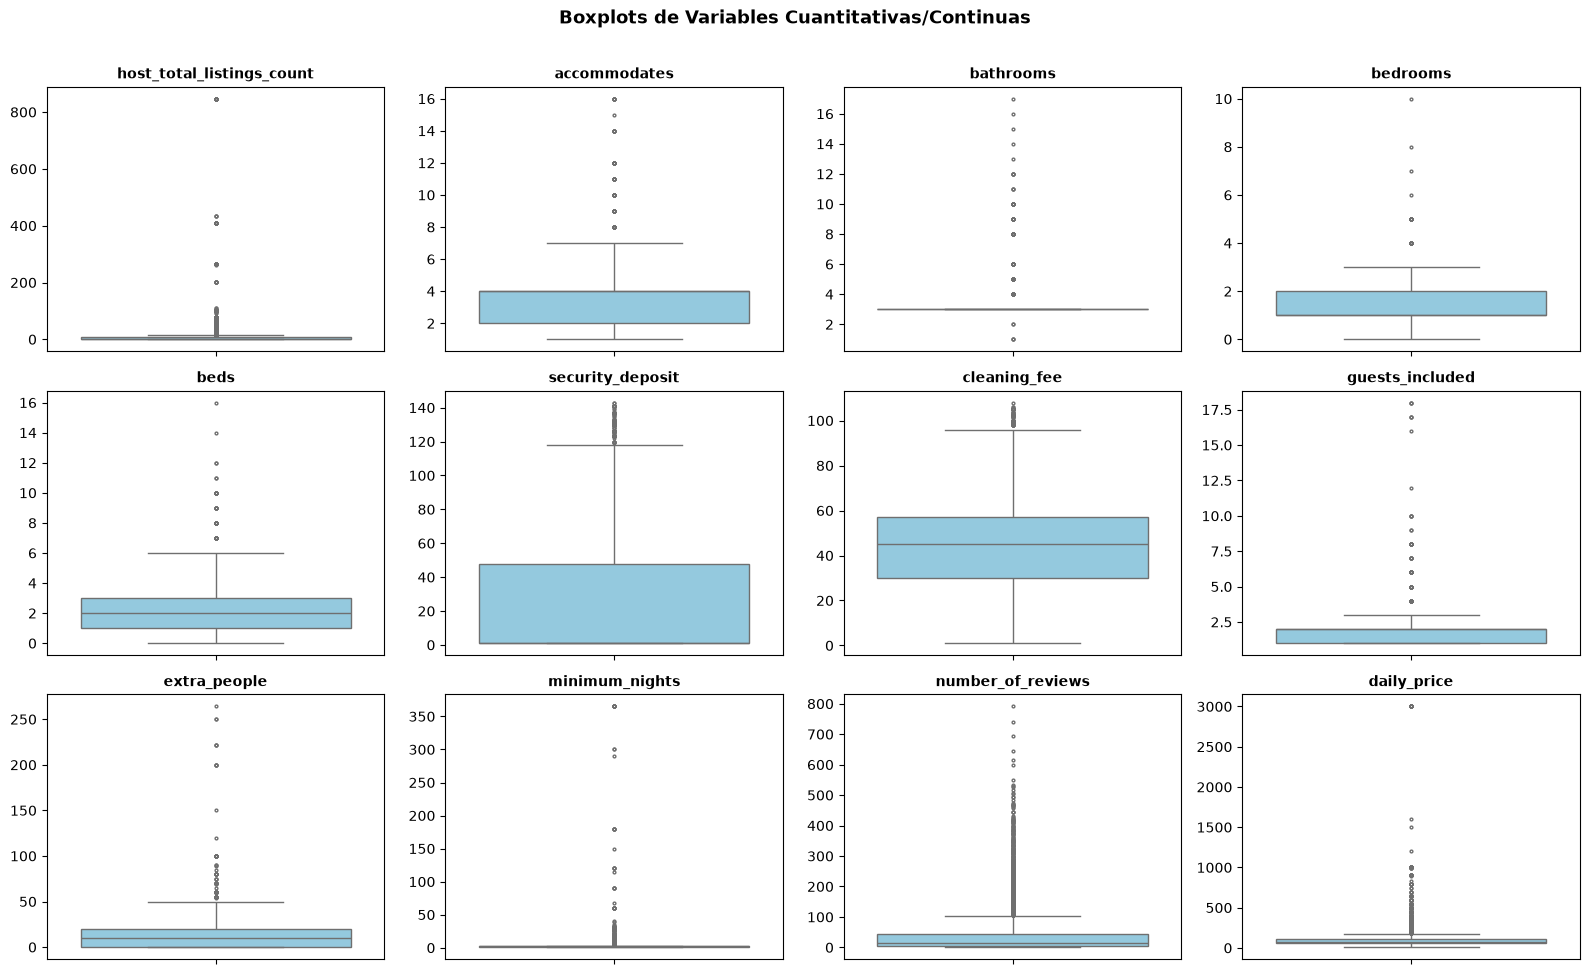

In [18]:
n_vars = len(cols_outliers)
n_cols = 4
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.2))
axes = axes.flatten()

for i, col in enumerate(cols_outliers):
  sns.boxplot(y=df_analisis[col], ax=axes[i], color="skyblue", fliersize=2)
  axes[i].set_title(col, fontsize=10, fontweight="bold")
  axes[i].set_ylabel("")

plt.suptitle(
    "Boxplots de Variables Cuantitativas/Continuas",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.show()

Todas las 12 variables analizadas presentan outliers analiticos o graficos, salvo excepciones puntuales:
* En los boxplots: Las 12 variables muestran puntos individuales por fuera de los bigotes superiores.
* En el metodo Tukey: Todas superan el corte.
* En el metodo $Z$-Score: 11 de las 12 variables tienen registros que se alejan a mas de 3 desvios estandar de la media. La unica que no presenta outliers bajo este criterio es cleaning_fee (0%).  

In [19]:
# Ver distribución de baños para detectar cargas erróneas
print(df_analisis["bathrooms"].value_counts().sort_index())

bathrooms
1        3
2        2
3     7863
4      155
5     1122
6       29
8      108
9       10
10      17
11       3
12       5
13       1
14       1
15       1
16       1
17       1
Name: count, dtype: int64


In [20]:
# Ver anomalías extremas en baños
display(df_analisis[df_analisis["bathrooms"] > 10][["accommodates", "bedrooms", "beds", "bathrooms", "daily_price"]])

,accommodates,bedrooms,beds,bathrooms,daily_price
14,5,1,4,17,290
473,8,3,4,14,652
724,11,5,8,11,650
1343,10,4,6,11,800
1904,14,5,7,12,490
2029,14,5,8,12,304
2099,8,4,4,12,400
3278,8,4,8,11,199
6241,12,5,8,12,630
6687,8,4,4,13,3000


Desde este analisis, concluimos en eliminar las filas: 14 y 7882 ya que son datos absurdos.

In [21]:
df_analisis = df_analisis.drop([14, 7882])

Ahora, vamos a comprobar que ninguna propiedad este poniendo su precio de acuerdo a una cantidad de huespedes que en realidad superan los que la propiedad puede acomodar.

In [22]:
# Filtrar filas donde los huéspedes incluidos superan la capacidad máxima
inconsistencias_huespedes = df_analisis[df_analisis['guests_included'] > df_analisis['accommodates']]

print(f"Cantidad de registros con inconsistencia lógica (guests_included > accommodates): {len(inconsistencias_huespedes)}")

# Visualizar las columnas clave de estos casos anómalos
if len(inconsistencias_huespedes) > 0:
    display(inconsistencias_huespedes[['accommodates', 'guests_included', 'extra_people', 'daily_price']])

Cantidad de registros con inconsistencia lógica (guests_included > accommodates): 23


,accommodates,guests_included,extra_people,daily_price
13,4,5,20,290
81,2,3,50,90
860,6,16,10,149
3102,2,4,20,80
3225,2,17,0,52
3371,2,17,0,52
3421,2,18,0,52
3551,2,18,0,63
4291,3,4,15,60
4405,2,4,10,150


Eliminamos estas filas, ya que representan una contradiccion: una propiedad no puede cobrar un precio base por una cantidad de huespedes que fisicamente no entran en la propiedad.

In [23]:
df_analisis = df_analisis[df_analisis['guests_included'] <= df_analisis['accommodates']]

### MATRIZ DE CORRELACION

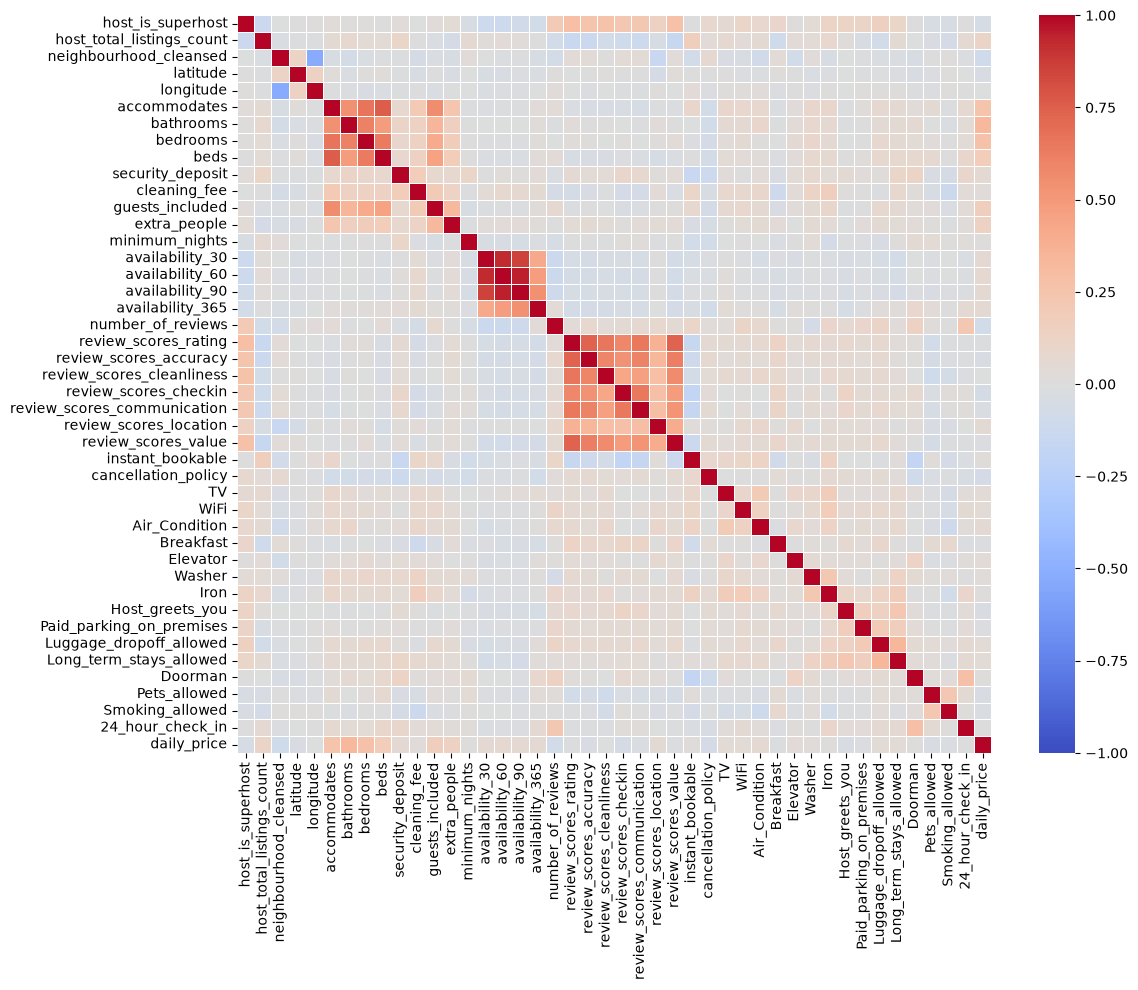

In [24]:
cols_para_corr = [
    col for col in df_analisis.columns if col not in ['id', 'host_id']
]

matriz_corr = df_analisis[cols_para_corr].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    matriz_corr,
    annot=False,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.tight_layout()
plt.savefig("matriz_correlacion.png", dpi=300)
plt.show()

* Podemos ver una relación positiva directa entre daily_price y las variables de dimensiones fisicas (bathrooms, bedrooms, accommodates). Esto es intuitivo ya que la capacidad y el tamaño del inmueble fijan la principal estructura de precios.

* Se detecta una alta correlacion cruzada dentro del bloque de capacidad (accommodates vs. beds) y en las metricas de disponibilidad temporal (availability_*).

* A su vez, podemos ver que las variables sobre reviews tienen una alta correlacion entre ellas.

A partir de este analisis, eliminaremos de nuestro modelo las siguientes variables:

* availability_30, availability_60, availability_90: En la matriz forman un bloque rojo entre ellas. La disponibilidad a 30, 60 y 90 días miden prácticamente lo mismo en distintas ventanas temporales cortas. Nos quedamos unicamente con availability_365, ya que captura la disponibilidad anual global del alojamiento sin duplicar informacion redundante.
* review_scores_accuracy, review_scores_cleanliness, review_scores_checkin, review_scores_communication, review_scores_location, review_scores_value: Todas estas metricas presentan bloques de correlacion muy elevados entre si (tonos anaranjados/rojos fuertes). Los huespedes tienden a calificar de manera globalmente similar todos los rubros, por lo que incluirlos a todos nos deja informacion repetida.
* beds: las variables accomodates, bedrooms, bathrooms y beds tienen correlacion entre si, pero consideramos que beds y accomodates tienen la mayor correlacion, por lo que eliminaremos la primera para nuestro modelo.
* latitud y longitud: a partir de la matriz de correlación, decidimos eliminar `latitude` y `longitude`, ya que aportan información geográfica parcialmente redundante con `neighbourhood_cleansed`. Además, al incluirlas en la regresión OLS se observaron problemas de multicolinealidad y condicionamiento numérico. Por eso, optamos por conservar únicamente el barrio como indicador de ubicación, simplificando el modelo.

In [25]:
df_analisis.drop(columns=[
    "availability_30", "availability_60", "availability_90", "latitude", "longitude",
    "review_scores_accuracy", "review_scores_cleanliness", "review_scores_checkin",
    "review_scores_communication", "review_scores_location", "review_scores_value",
    "beds"
], inplace=True)

## SELECCION DE VARIABLES

### 1) Identificación e información del anfitrión

- ❌**`id`**: Identificador único del apartamento.
- ❌**`host_id`**: Identificador único del anfitrión.
- ❌**`host_location`**: Indica si el anfitrión reside en Italia. `1 = Italia`, `0 = fuera de Italia`.
- ❌**`host_response_time`**: Indica la rapidez de respuesta del anfitrión. `1 = rápida`, `0 = lenta`.
- ❌**`host_response_rate`**: Porcentaje de consultas respondidas por el anfitrión.
- ✅**`host_is_superhost`**: Indica si el anfitrión tiene la categoría Superhost. `1 = sí`, `0 = no`.
- ✅**`host_total_listings_count`**: Cantidad total de propiedades publicadas por el anfitrión.
- ❌**`host_has_profile_pic`**: Indica si el anfitrión tiene una foto de perfil. `1 = sí`, `0 = no`.
- ❌**`host_identity_verified`**: Indica si Airbnb verificó la identidad del anfitrión. `1 = sí`, `0 = no`.

### 2) Ubicación del alojamiento


- ✅**`neighbourhood_cleansed`**: Barrio o zona de la ciudad donde se encuentra el alojamiento, según la clasificación normalizada de Airbnb.
- ❌zipcode`**: Código postal del alojamiento.
- ❌**`latitude`**: Latitud geográfica del alojamiento.
- ❌**`longitude`**: Longitud geográfica del alojamiento.

### 3) Características del alojamiento


- ❌**`room_type`**: Tipo de alojamiento ofrecido. En este dataset se consideran únicamente apartamentos o viviendas completas.
- ✅**`accommodates`**: Cantidad máxima de huéspedes que puede alojar la propiedad.
- ✅**`bathrooms`**: Cantidad de baños del alojamiento.
- ✅**`bedrooms`**: Cantidad de dormitorios del alojamiento.
- ❌**`beds`**: Cantidad de camas disponibles.
- ❌**`bed_type`**: Tipo de cama ofrecida, representado mediante categorías.


### 4) Precios y condiciones de reserva

- ❌**`security_deposit`**: Depósito de garantía solicitado por el anfitrión.
- ❌**`cleaning_fee`**: Cargo adicional por limpieza del alojamiento.
- ✅**`guests_included`**: Cantidad de huéspedes incluidos en el precio base.
- ❌**`extra_people`**: Cargo adicional por cada huésped extra.
- ✅**`minimum_nights`**: Cantidad mínima de noches exigida para reservar el alojamiento.

In [26]:
df_analisis.drop(columns=["security_deposit", "cleaning_fee", "extra_people"], inplace=True)

Justificación: estas variables forman parte de la estructura de precios definida por el anfitrión y pueden estar estrechamente relacionadas con el propio daily_price.

Se decide excluirlas para que el modelo estime el precio por noche principalmente a partir de características del alojamiento, y no de otros importes fijados simultáneamente por el anfitrión.

Esto no implica necesariamente que constituyan data leakage, sino que responde al enfoque elegido para el problema de predicción.

Se conservan minimum_nights y guests_included, ya que describen condiciones de reserva que pueden influir en el precio base.

### 5) Disponibilidad

- ❌**`availability_30`**: Cantidad de días disponibles para reservar durante los próximos 30 días.
- ❌**`availability_60`**: Cantidad de días disponibles para reservar durante los próximos 60 días.
- ❌**`availability_90`**: Cantidad de días disponibles para reservar durante los próximos 90 días.
- ✅**`availability_365`**: Cantidad de días disponibles para reservar durante los próximos 365 días.

### 6) Reseñas y evaluaciones

- ✅**`number_of_reviews`**: Cantidad total de reseñas recibidas por el alojamiento.
- ✅**`review_scores_rating`**: Puntuación general del alojamiento otorgada por los huéspedes (escala de 0 a 100).
- ❌**`review_scores_accuracy`**: Puntuación sobre qué tan precisa es la descripción del alojamiento (0 a 10).
- ❌**`review_scores_cleanliness`**: Puntuación de limpieza del alojamiento (0 a 10).
- ❌**`review_scores_checkin`**: Puntuación del proceso de ingreso o check-in (0 a 10).
- ❌**`review_scores_communication`**: Puntuación de la comunicación con el anfitrión (0 a 10).
- ❌**`review_scores_location`**: Puntuación de la ubicación del alojamiento (0 a 10).
- ❌**`review_scores_value`**: Puntuación de la relación calidad-precio del alojamiento (0 a 10).


### 7) Políticas y condiciones adicionales

- ❌**`instant_bookable`**: Indica si el alojamiento permite realizar reservas instantáneas sin aprobación previa del anfitrión.
- ❌**`cancellation_policy`**: Tipo de política de cancelación establecida por el anfitrión.
- ❌**`require_guest_profile_picture`**: Indica si se exige que el huésped tenga una foto de perfil.
- ❌**`require_guest_phone_verification`**: Indica si se exige que el huésped tenga su número telefónico verificado.


In [27]:
df_analisis.drop(columns=["instant_bookable","cancellation_policy",], inplace=True)

Se eliminan todas estas, ya que no depende del alojamiento en si, sino del anfitrion

### 8) Servicios y comodidades

- ✅**`TV`**: Disponibilidad de televisión.
- ✅**`WiFi`**: Disponibilidad de conexión inalámbrica a Internet.
- ✅**`Air_Condition`**: Disponibilidad de aire acondicionado.
- ❌**`Wheelchair_accessible`**: Accesibilidad para personas que utilizan silla de ruedas.
- ✅**`Kitchen`**: Disponibilidad de cocina.
- ✅**`Breakfast`**: Desayuno incluido u ofrecido.
- ✅**`Elevator`**: Disponibilidad de ascensor.
- ✅**`Heating`**: Disponibilidad de calefacción.
- ✅**`Washer`**: Disponibilidad de lavarropas.
- ✅**`Iron`**: Disponibilidad de plancha.
- ✅**`Host_greets_you`**: Indica si el anfitrión recibe personalmente a los huéspedes.
- ✅**`Paid_parking_on_premises`**: Disponibilidad de estacionamiento pago dentro de la propiedad.
- ✅**`Luggage_dropoff_allowed`**: Posibilidad de dejar el equipaje antes del check-in o después del check-out.
- ✅**`Long_term_stays_allowed`**: Indica si se permiten estadías prolongadas.
- ✅**`Doorman`**: Disponibilidad de portero o servicio de recepción.
- ✅**`Pets_allowed`**: Indica si se permiten mascotas.
- ✅**`Smoking_allowed`**: Indica si se permite fumar.
- *❌*`Suitable_for_events`**: Indica si el alojamiento permite organizar eventos.
- ✅**`24_hour_check_in`**: Disponibilidad de ingreso al alojamiento durante las 24 horas.

## Análisis exploratorio de la variable objetivo

In [28]:
df_analisis.columns

Index(['host_is_superhost', 'host_total_listings_count',
       'neighbourhood_cleansed', 'accommodates', 'bathrooms', 'bedrooms',
       'guests_included', 'minimum_nights', 'availability_365',
       'number_of_reviews', 'review_scores_rating', 'TV', 'WiFi',
       'Air_Condition', 'Breakfast', 'Elevator', 'Washer', 'Iron',
       'Host_greets_you', 'Paid_parking_on_premises',
       'Luggage_dropoff_allowed', 'Long_term_stays_allowed', 'Doorman',
       'Pets_allowed', 'Smoking_allowed', '24_hour_check_in', 'daily_price'],
      dtype='str')

In [29]:
df_analisis["daily_price"].describe()

count    9297.000000
mean      103.707863
std       138.088896
min        10.000000
25%        59.000000
50%        75.000000
75%       106.000000
max      3000.000000
Name: daily_price, dtype: float64

In [30]:

bins = [0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 2000, 3000]

# 2. Definir las etiquetas (labels) descriptivas para cada rango
labels = [
    '0-100', '100-200', '200-300', '300-400', '400-500',
    '500-600', '600-700', '700-800', '800-900', '900-1000',
    '1000-2000', '2000-3000'
]

df_aux = df_analisis.copy()
df_aux["rango_precio"] = pd.cut(
    df_aux['daily_price'],
    bins=bins,
    labels=labels,
    right=True,
    include_lowest=True
)

# Vemos cuantas filas estan en cada rango de valores
conteo_rangos = df_aux['rango_precio'].value_counts().sort_index()

print(conteo_rangos)

rango_precio
0-100        6900
100-200      1824
200-300       350
300-400        80
400-500        57
500-600        21
600-700        12
700-800        10
800-900        10
900-1000       18
1000-2000       3
2000-3000      12
Name: count, dtype: int64


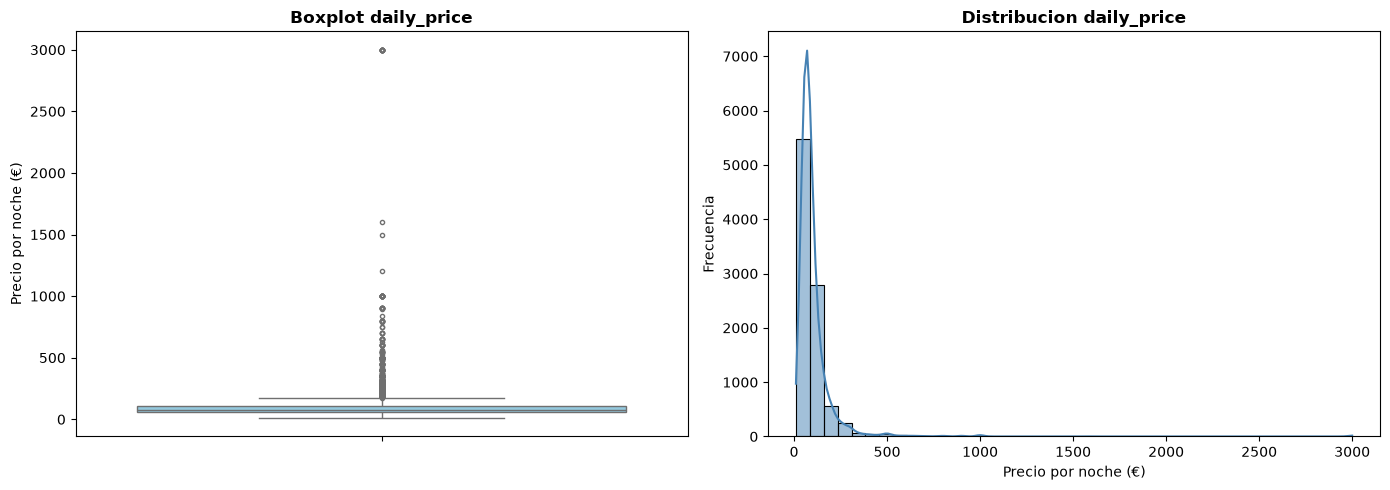

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot
sns.boxplot(y=df_analisis['daily_price'], ax=axes[0], color='skyblue', fliersize=3)
axes[0].set_title('Boxplot daily_price', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Precio por noche (€)')

# Histograma
sns.histplot(df_analisis['daily_price'], kde=True, ax=axes[1], color='steelblue', bins=40)
axes[1].set_title('Distribucion daily_price', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Precio por noche (€)')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

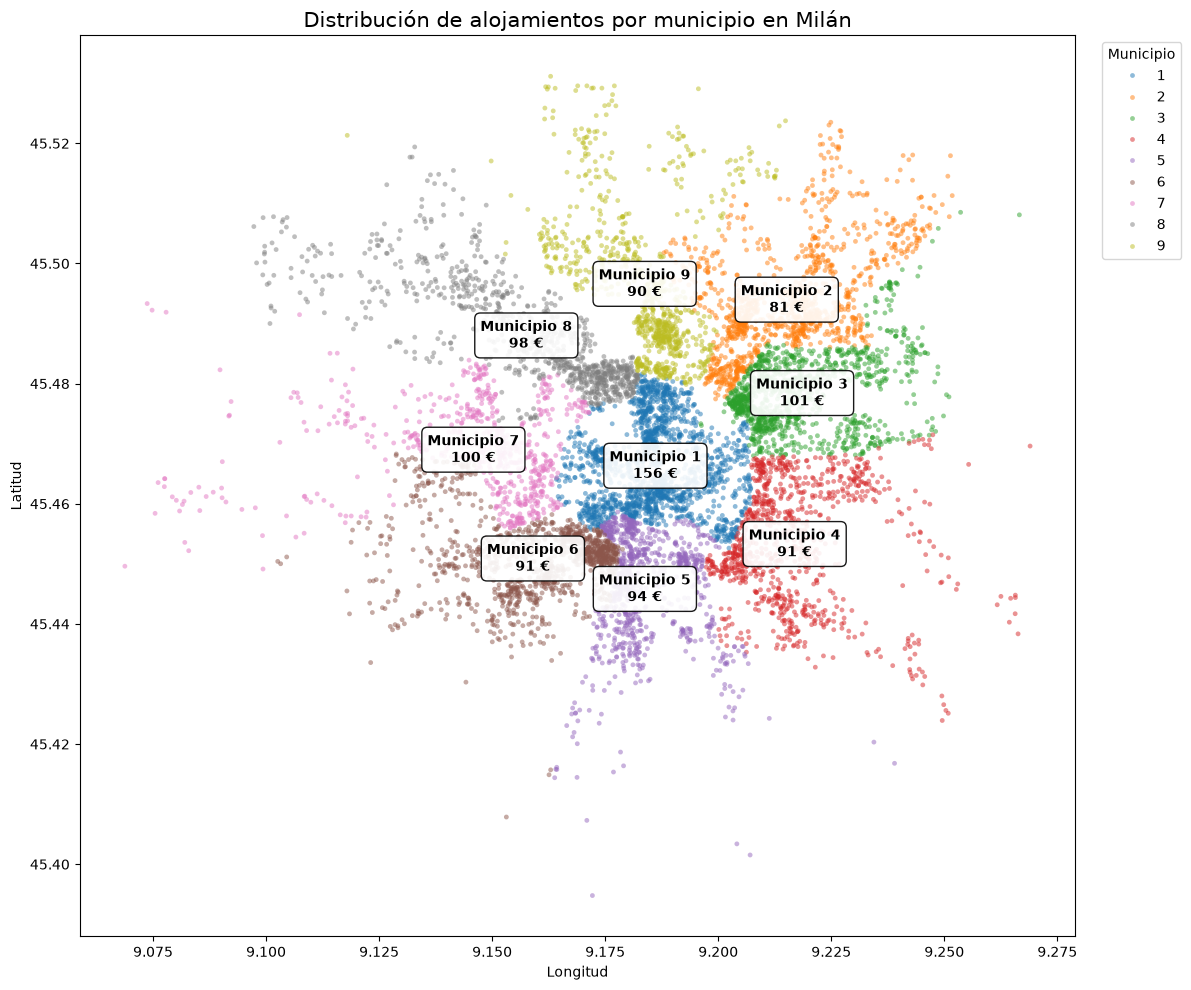

In [32]:
data = df_raw[
    ["latitude", "longitude", "neighbourhood_cleansed", "daily_price"]
].copy()

# Convertimos municipios a categorías
data["municipio"] = data["neighbourhood_cleansed"].astype(str)

# Estadísticas por municipio
municipios = (
    data.groupby("municipio")
    .agg(
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),
        precio_medio=("daily_price", "mean"),
    )
    .reset_index()
)

# Gráfico
fig, ax = plt.subplots(figsize=(12, 10))

sns.scatterplot(
    data=data,
    x="longitude",
    y="latitude",
    hue="municipio",
    palette="tab10",
    s=12,
    alpha=0.5,
    linewidth=0,
    ax=ax,
)

# Etiquetas con municipio y precio mediano
for _, row in municipios.iterrows():
    ax.annotate(
        f"Municipio {row['municipio']}\n"
        f"{row['precio_medio']:.0f} €",
        xy=(row["longitude"], row["latitude"]),
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor="black",
            alpha=0.9,
        ),
    )

ax.set_title(
    "Distribución de alojamientos por municipio en Milán",
    fontsize=15,
)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

ax.legend(
    title="Municipio",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()


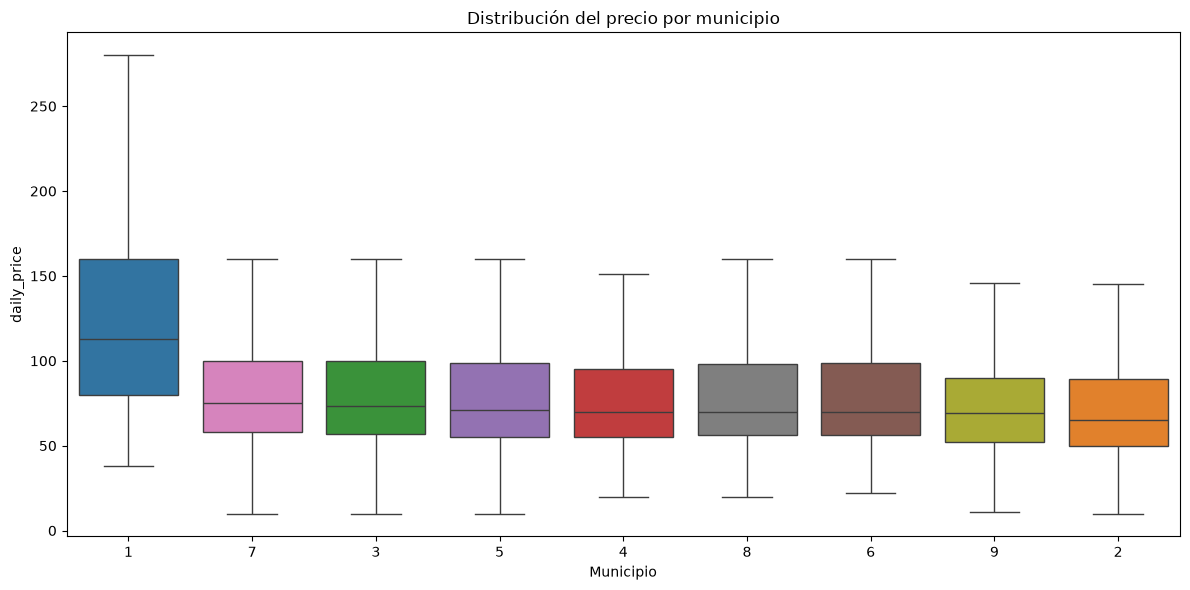

In [33]:
# Preparación
data = df_raw[
    ["latitude", "longitude", "neighbourhood_cleansed", "daily_price"]
].dropna().copy()

# Ordenar municipios según el precio mediano
orden = (
    data.groupby("neighbourhood_cleansed")["daily_price"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=data,
    x="neighbourhood_cleansed",
    y="daily_price",
    order=orden,
    hue="neighbourhood_cleansed",
    palette="tab10",
    showfliers=False,
    legend=False,
)

plt.title("Distribución del precio por municipio")
plt.xlabel("Municipio")
plt.ylabel("daily_price")
plt.tight_layout()
plt.show()

De estos gráficos vemos como la mayor diferencia de precios se da entre el Municipio 1 (céntrico) y los demás

Observemos la distribución de los precios por barrio

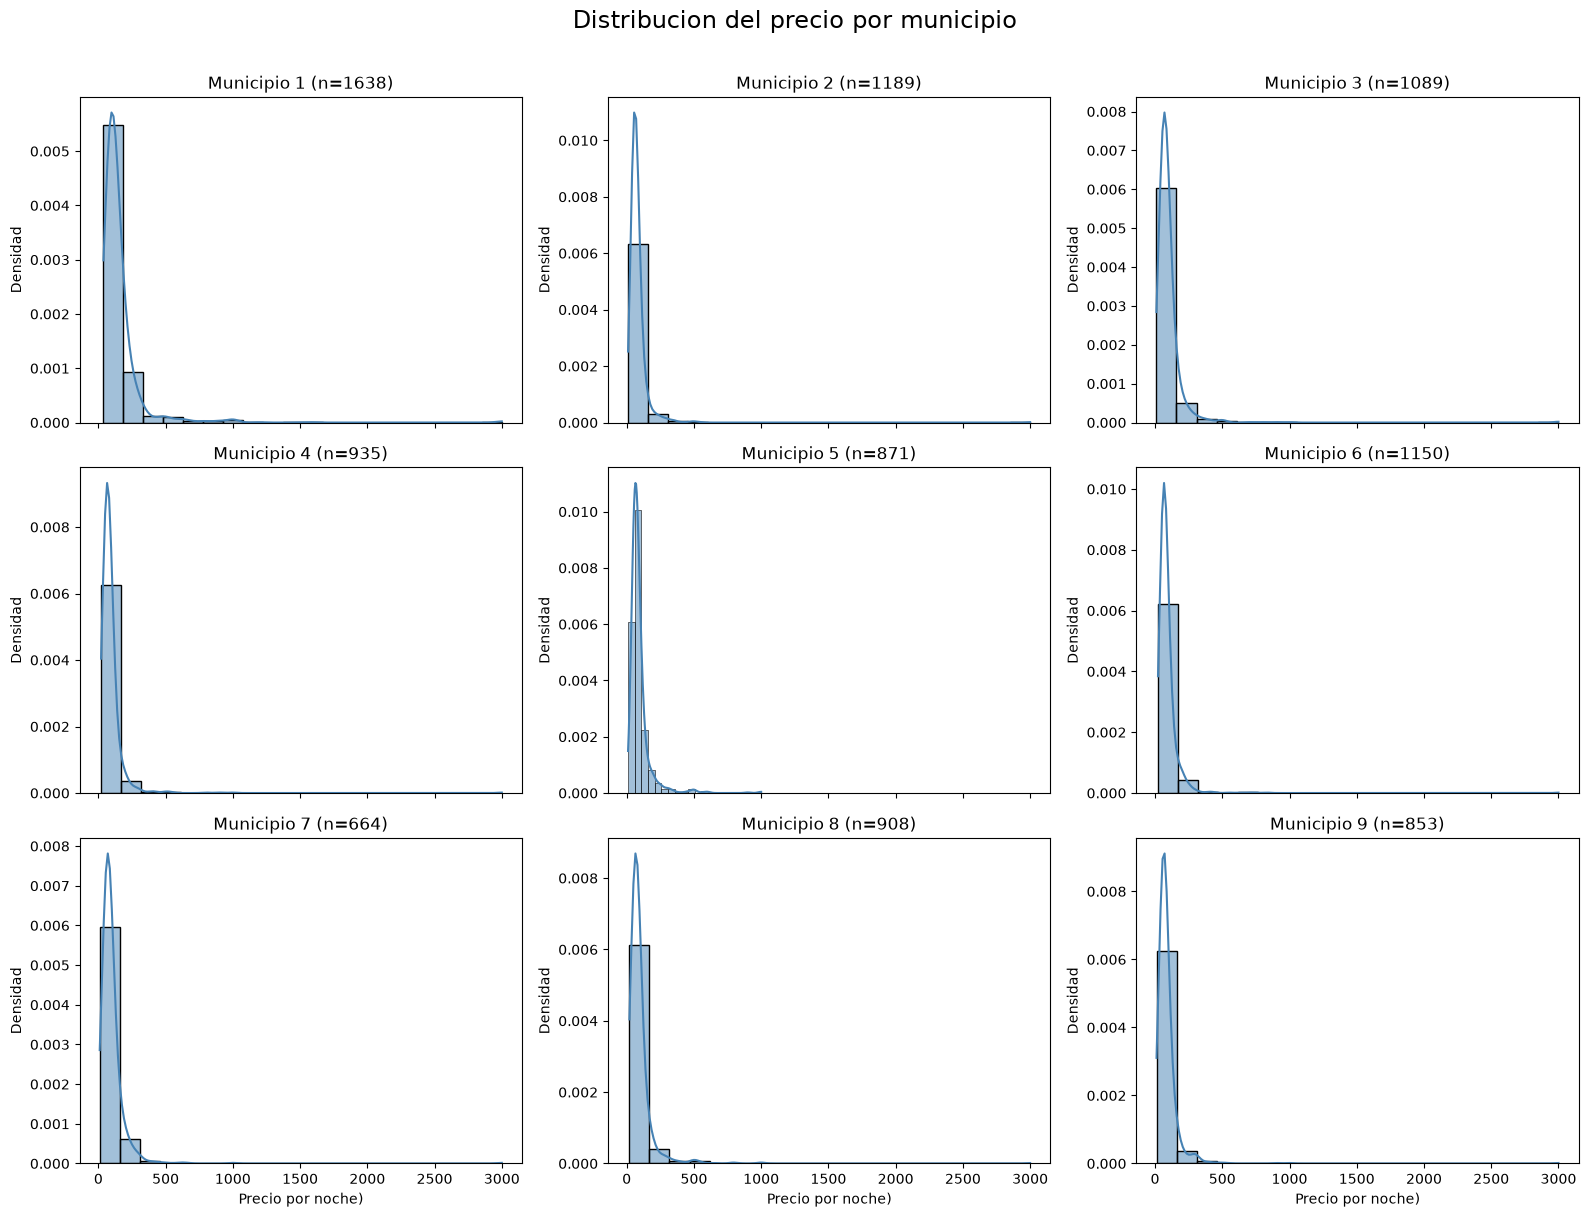

In [34]:
# Municipios ordenados
municipios = sorted(df_analisis["neighbourhood_cleansed"].unique())

def plot_histogramas_por_municipio(columna):
    n_cols = 3
    n_rows = ceil(len(municipios) / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(16, 4 * n_rows),
        sharex=True
    )

    axes = np.array(axes).flatten()

    for ax, municipio in zip(axes, municipios):
        subset = df_analisis[
            df_analisis["neighbourhood_cleansed"] == municipio
        ]

        sns.histplot(
            data=subset,
            x=columna,
            bins=20,
            kde=True,
            stat="density",
            color="steelblue",
            ax=ax
        )

        ax.set_title(
            f"Municipio {municipio} (n={len(subset)})"
        )
        ax.set_xlabel("Precio por noche)")
        ax.set_ylabel("Densidad")

    fig.suptitle("Distribucion del precio por municipio", fontsize=17, y=1.01)
    plt.tight_layout()
    plt.show()

plot_histogramas_por_municipio("daily_price")

Hacemos una transformación logaritmica

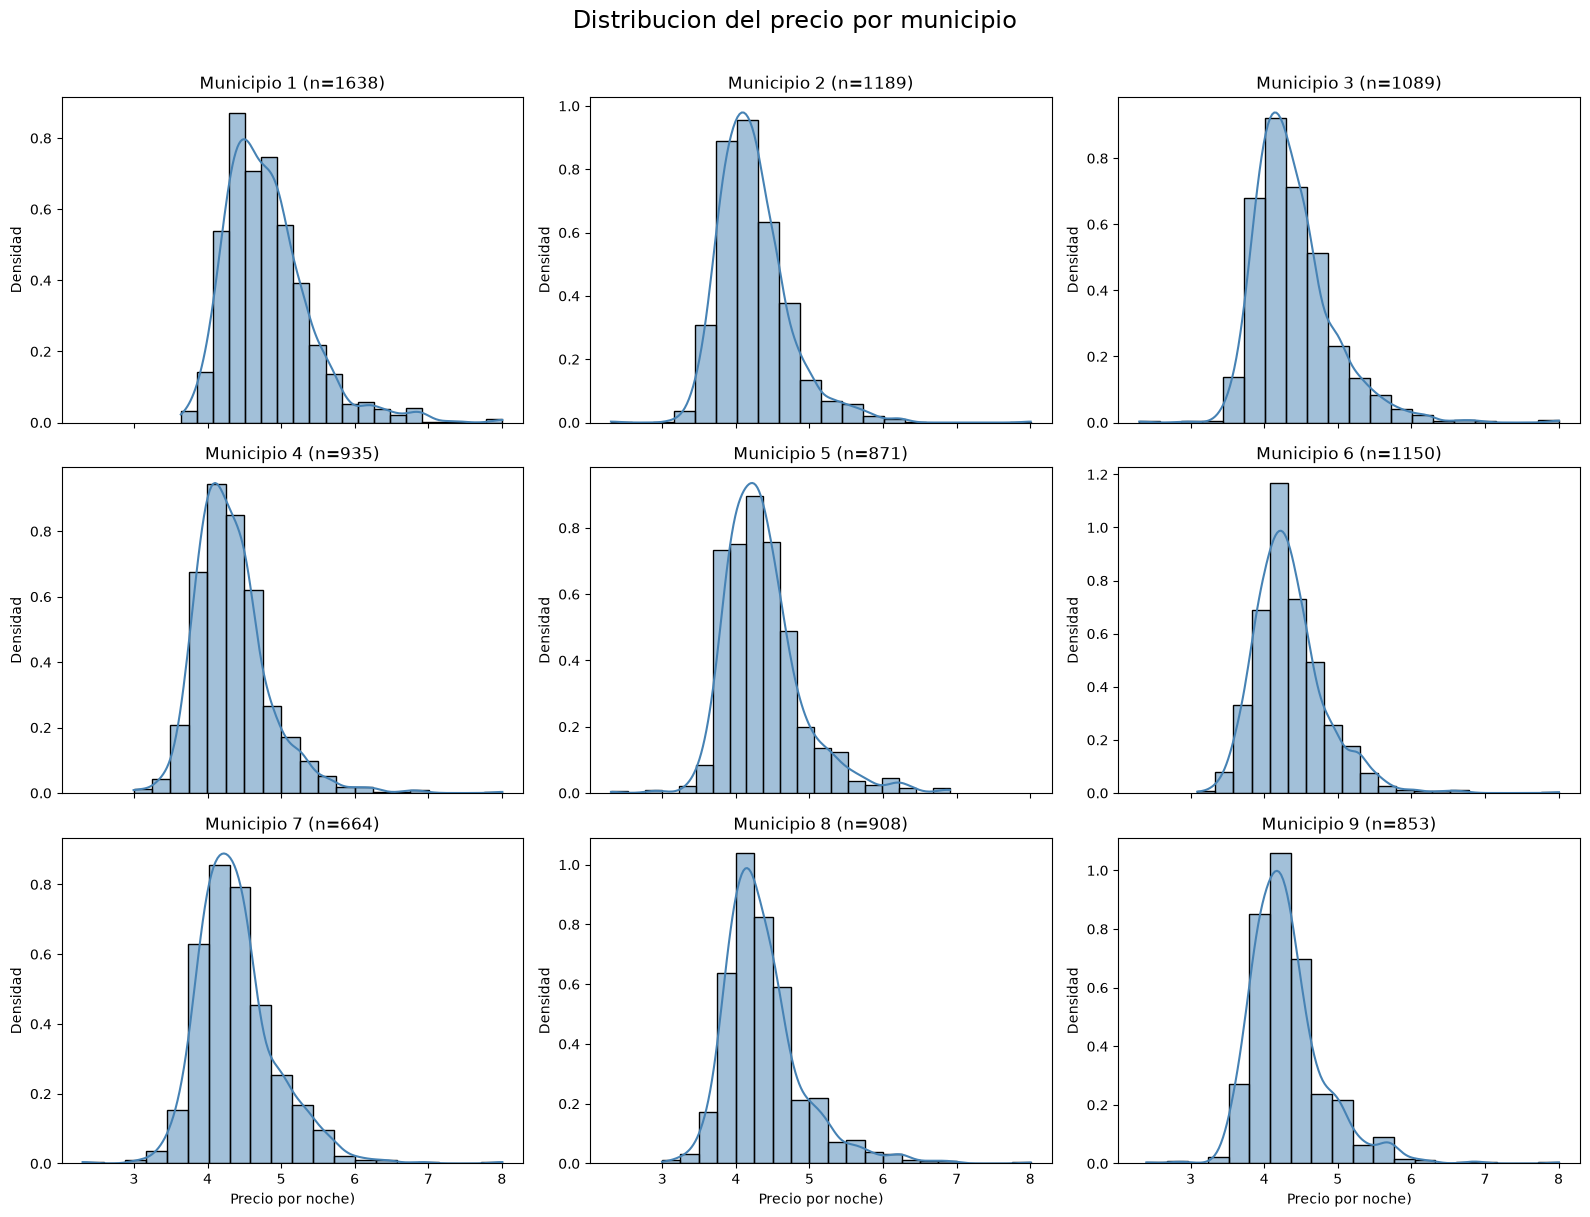

In [35]:
# df_analisis["log_daily_price"] = np.log(df_analisis["daily_price"]) # log(1 + x) para que quede positivo
df_analisis["log_daily_price"] = np.log(df_analisis["daily_price"])

plot_histogramas_por_municipio("log_daily_price")

POR QUE HACEMOS ESTA TRANSFORMACION?
* La rgresion lineal asume que los errores se distribuyen de manera normal. Los precios de los alquileres tienen una asimetria positiva extrema a derecha. Al aplicar el logaritmo, la distribucion se vuelve lognormal / simetrica, permitiendo que los residuos cumplan con la normalidad.
* En la escala original en euros, a medida que el departamento es máa grande o lujoso, el error de prediccion tiende a ser mucho mas grande. El logaritmo comprime las escalas altas y estabiliza la varianza de los errores a lo largo de todo el rango de precios.
* Si quisiesemos usar daily_price original en un modelo lineal estricto, nos veriamos obligados a eliminar outliers de la cola superior para que no arruinen la recta. Usar el logaritmo nos permite conservar el 100% de la muestra sin perder las propiedades de lujo legitimas.

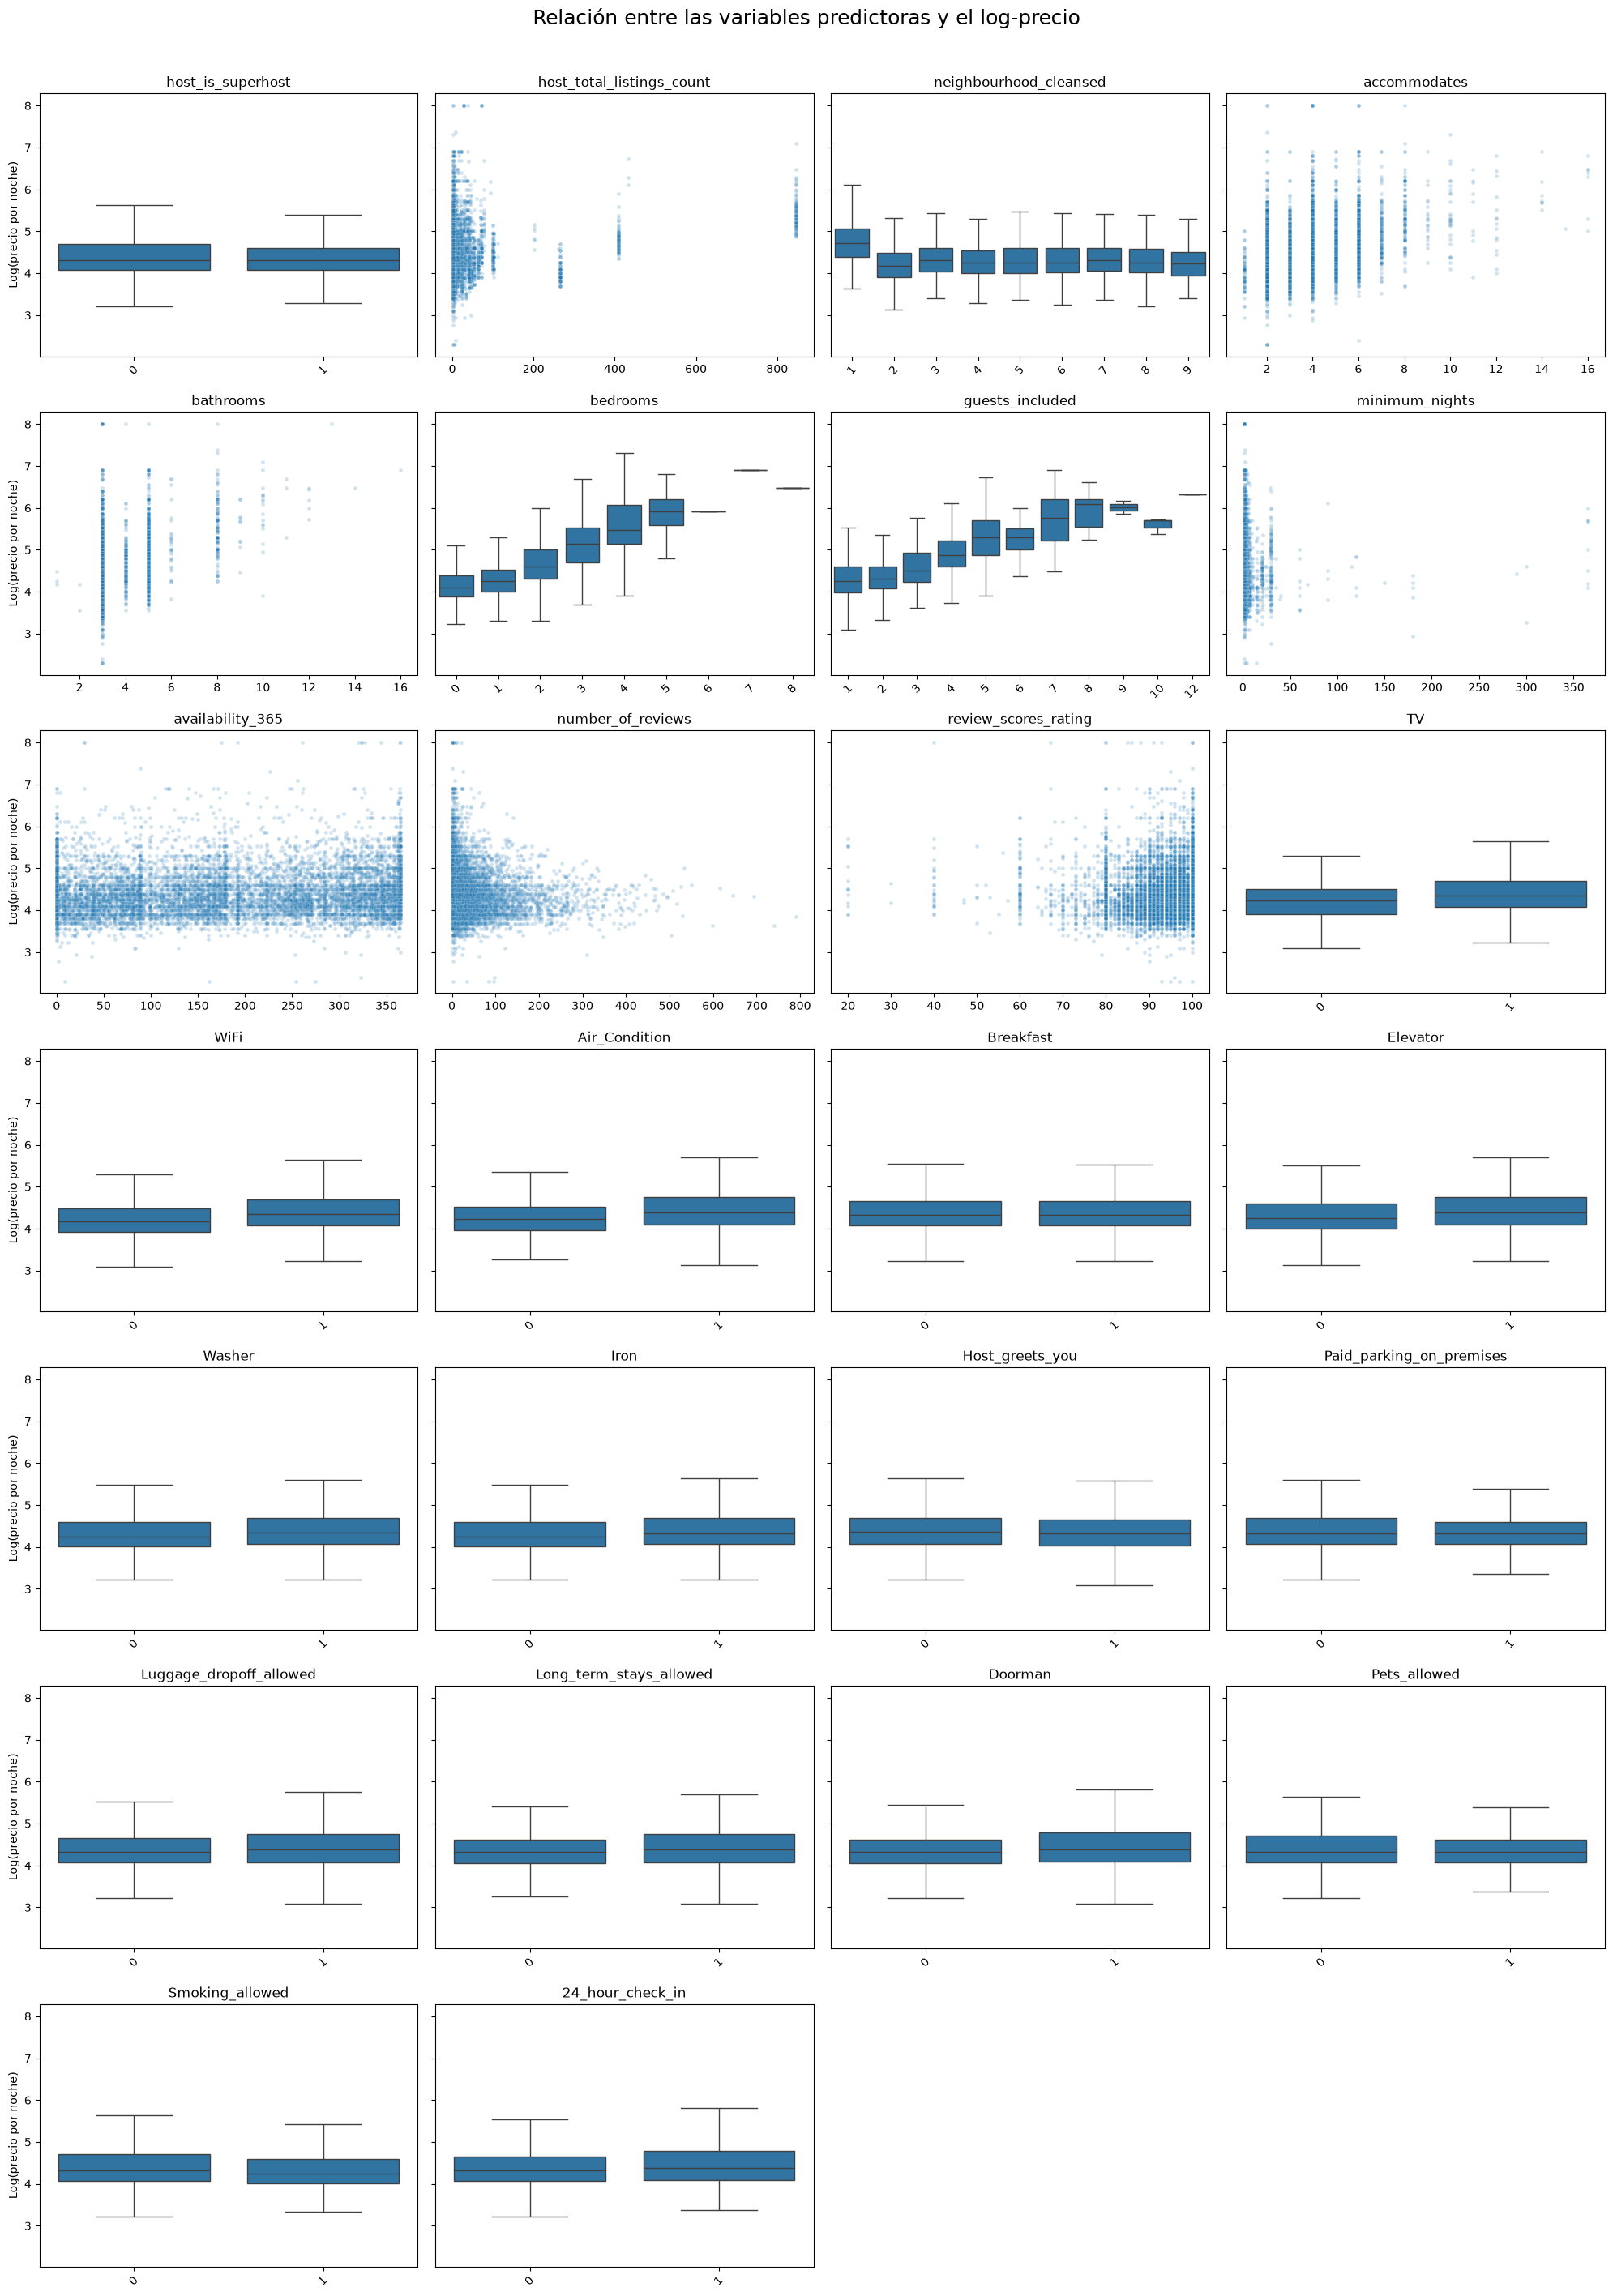

In [36]:
target = "log_daily_price"

# Excluir los targets
features = df_analisis.columns.drop(["daily_price", target])

# Configuración de la grilla
n_cols = 4
n_rows = int(np.ceil(len(features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, 4 * n_rows),
    sharey=True
)

axes = axes.flatten()

for ax, col in zip(axes, features):

    # Variables categóricas o discretas con pocos valores
    es_categorica = (
        not pd.api.types.is_numeric_dtype(df_analisis[col])
        or col == "neighbourhood_cleansed"
        or df_analisis[col].nunique() <= 12
    )

    if es_categorica:
        sns.boxplot(
            data=df_analisis,
            x=col,
            y=target,
            showfliers=False,
            ax=ax
        )
        ax.tick_params(axis="x", rotation=45)

    else:
        sns.scatterplot(
            data=df_analisis,
            x=col,
            y=target,
            alpha=0.2,
            s=12,
            ax=ax
        )

    ax.set_title(col, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Log(precio por noche)")

# Eliminar ejes sobrantes
for ax in axes[len(features):]:
    ax.remove()

fig.suptitle(
    "Relación entre las variables predictoras y el log-precio",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()

### Relación entre las variables predictoras y el precio

**Variables categóricas:** Se observan diferencias en el precio según el barrio (`neighbourhood_cleansed`), especialmente en el barrio 1, que presenta valores más altos. Algunas comodidades, como aire acondicionado, WiFi, TV y ascensor, también parecen estar asociadas a precios ligeramente mayores. En cambio, características como ser superhost, permitir mascotas o fumar no muestran diferencias importantes.

**Variables numéricas:** Las relaciones más claras aparecen en las variables vinculadas al tamaño y capacidad del alojamiento (`bedrooms`, `accommodates` y `guests_included`), donde se observa una tendencia positiva con el precio. Por otro lado, variables como `minimum_nights`, `availability_365` y `host_total_listings_count` no muestran tendencias evidentes. Tampoco se observa una relación lineal clara con las coordenadas geográficas.

**En general**, el tamaño, la capacidad y la ubicación parecen ser los factores más relacionados con el precio. De todas formas, estas son asociaciones visuales y algunas variables podrían aportar información al combinarse con otras.

Transformaciones finales y guardado del dataset filtrado

In [37]:
# Antes de tomar la muestra cambiamos el nombre de la variable 24_hour_check_in
# porque al tener un número adelante no lo toma bien en la formula para el OLS.
df_eda = df_analisis.rename(columns={"24_hour_check_in": "check_in_24_hour"})

# Eliminamos el daily price ya que cambiamos la variable objetivo a su logaritmo
df_eda.drop(columns="daily_price", inplace=True)

# Guardamos el dataset filtrado y transformado
df_eda.to_csv(PROJECT_DIR / "datos/procesados/milan_airbnb_filtrado.csv", index=False)

<a href="https://colab.research.google.com/github/santidrelew/tp-mpg/blob/main/notebooks/02_extraccion_muestra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **2 - Extracción de la muestra**

In [38]:
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !git clone https://github.com/santidrelew/tp-mpg.git
    %cd tp-mpg

In [39]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

In [40]:
# Cargamos los datasets
PROJECT_DIR = Path().resolve() if EN_COLAB else Path().resolve().parent
DATA_BASE_DIR = PROJECT_DIR / "datos" / "procesados"

df = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_filtrado.csv")

Vamos a hacer un muestreo estratificado tomando como estrato la variable 'neighbourhood_cleansed'. Esto es porque las tarifas y amenidades difieren sustancialmente entre el centro historico y las comunas perifericas. Un muestreo puramente aleatorio corria el riesgo de subestimar zonas de menor densidad de oferta (como la comuna 7).

In [41]:
N_MUESTRA = 750
zona = "neighbourhood_cleansed"
fraccion = N_MUESTRA / len(df)

df_muestra = pd.concat([
    grupo.sample(frac=fraccion, random_state=42)
    for _, grupo in df.groupby(zona, sort=True)
])

if len(df_muestra) > N_MUESTRA:
    df_muestra = df_muestra.sample(n=N_MUESTRA, random_state=42)

assert zona in df_muestra.columns
assert len(df_muestra) == N_MUESTRA

In [42]:
TARGET = "log_daily_price"

media_pop = df[TARGET].mean()
var_pop = df[TARGET].var()

media_mue = df_muestra[TARGET].mean()
var_mue = df_muestra[TARGET].var()

tabla_validacion = pd.DataFrame(
    {
        "Metrica": [
            "Media ",
            "Varianza",
            "Desvio Estándar ",
            "Mediana ",
        ],
        "Poblacion": [
            round(media_pop, 2),
            round(var_pop, 2),
            round(df[TARGET].std(), 2),
            round(df[TARGET].median(), 2),
        ],
        "Muestra (n=750)": [
            round(media_mue, 2),
            round(var_mue, 2),
            round(df_muestra[TARGET].std(), 2),
            round(df_muestra[TARGET].median(), 2),
        ],
        "Diferencia Relativa (%)": [
            round(abs(media_pop - media_mue) / media_pop * 100, 2),
            round(abs(var_pop - var_mue) / var_pop * 100, 2),
            round(
                abs(df[TARGET].std() - df_muestra[TARGET].std())
                / df[TARGET].std()
                * 100,
                2,
            ),
            round(
                abs(df[TARGET].median() - df_muestra[TARGET].median())
                / df[TARGET].median()
                * 100,
                2,
            ),
        ],
    }
)

tabla_validacion

,Metrica,Poblacion,Muestra (n=750),Diferencia Relativa (%)
0,Media,4.42,4.40,0.47
1,Varianza,0.31,0.28,10.06
2,Desvio Estándar,0.56,0.53,5.17
3,Mediana,4.32,4.32,0.00



Poblacion
Percentil 95: 5.48 | Percentil 99: 6.21 | Máximo: 8.01

Muestra
Percentil 95: 5.30 | Percentil 99: 6.18 | Máximo: 7.09


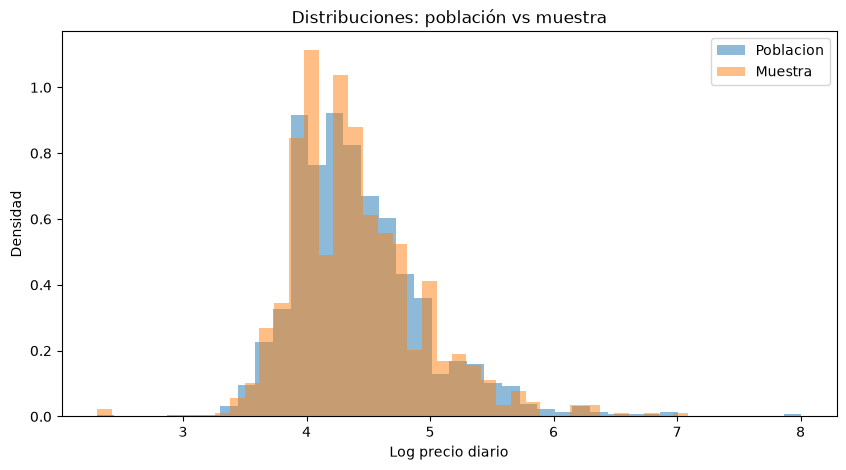

In [43]:
for nombre, datos in [
    ("Poblacion", df[TARGET]),
    ("Muestra", df_muestra[TARGET])
]:
    print(f"\n{nombre}")
    print(
        f"Percentil 95: {datos.quantile(0.95):.2f} | "
        f"Percentil 99: {datos.quantile(0.99):.2f} | "
        f"Máximo: {datos.max():.2f}"
    )
    
plt.figure(figsize=(10, 5))

plt.hist(
    df[TARGET],
    bins=40,
    density=True,
    alpha=0.5,
    label="Poblacion"
)

plt.hist(
    df_muestra[TARGET],
    bins=40,
    density=True,
    alpha=0.5,
    label="Muestra"
)

plt.xlabel("Log precio diario")
plt.ylabel("Densidad")
plt.title("Distribuciones: población vs muestra")
plt.legend()
plt.show()

In [44]:
proporciones = pd.DataFrame({
    "Base (%)": df[zona].value_counts(normalize=True) * 100,
    "Muestra (%)": df_muestra[zona].value_counts(normalize=True) * 100,
}).fillna(0).sort_index()
proporciones["Diferencia (p. p.)"] = (
    proporciones["Muestra (%)"] - proporciones["Base (%)"]
)

display(proporciones.round(2))

,Base (%),Muestra (%),Diferencia (p. p.)
neighbourhood_cleansed,,,
1,17.62,17.60,-0.02
2,12.79,12.80,0.01
3,11.71,11.73,0.02
4,10.06,10.00,-0.06
5,9.37,9.33,-0.04
6,12.37,12.40,0.03
7,7.14,7.20,0.06
8,9.77,9.73,-0.03
9,9.18,9.20,0.02


Como la media del log-precio difiere solo un 0,47 % respecto de la base filtrada y la mediana que es menos sensible a los valores extremos, coincide en 4.33 podemos decir que la muestra refleja bien el centro de la distribucion. Además, conserva las proporciones de anuncios por zona con una diferencia maxima 0.06 puntos porcentuales.

En cuanto a la varianza y el desvio ambos son menores en la muestra, con diferencias del 10,06 % y del 5,17 %, respectivamente. Una posible explicación es que la muestra haya captado menos observaciones de la parte mas extrema de la distribuciin. Esto tambien se observa al comparar los percentiles. Estas diferencias por si solas no indican un sesgo de muestreo.

El uso de `log_daily_price` permite comprimir las diferencias entre los precios mas elevados y moderar su influencia en la regresión aunque no elimina porcompleto  el efecto de los valores extremos.

In [45]:
# Guardamos la muestra
df_muestra.to_csv(DATA_BASE_DIR / "milan_airbnb_muestra.csv", index=False)

<a href="https://colab.research.google.com/github/santidrelew/tp-mpg/blob/main/notebooks/03_OLS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3 - Regresión con OLS

In [46]:
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !git clone https://github.com/santidrelew/tp-mpg.git
    %cd tp-mpg

In [47]:
# Importamos todas las librerías necesarias
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.formula.api as smf


In [48]:
# Cargamos los datasets
PROJECT_DIR = Path().resolve() if EN_COLAB else Path().resolve().parent
DATA_BASE_DIR = PROJECT_DIR / "datos" / "procesados"

df = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_filtrado.csv")
df_muestra = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_muestra.csv")

In [49]:
TARGET = "log_daily_price"
FEATURES = [c for c in df.columns if c != TARGET]
CATEGORICAS = ["neighbourhood_cleansed"]

Creamos una unica funcion para usar en los 4 casos y no tener que repetir codigo:

In [50]:
def construir_formula(target: str, variables: list, categoricas: list) -> str:
    terminos = [f"C({v})" if v in categoricas else v for v in variables]
    return f"{target} ~ " + " + ".join(terminos)


def calcular_metricas(modelo, df_data: pd.DataFrame, target: str) -> dict:
    y_true = df_data[target]
    y_pred = modelo.predict(df_data)

    return {
        "N Variables": int(modelo.df_model),
        "R2": r2_score(y_true, y_pred),
        "R2 Ajustado": modelo.rsquared_adj,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    }

Primero, hacemos la regresion con todas las variables EDA de nuestro dataset entero:

In [51]:
formula_completa = construir_formula(TARGET, FEATURES, CATEGORICAS)
modelo_completo = smf.ols(formula=formula_completa, data=df).fit()

print(modelo_completo.summary())

                            OLS Regression Results                            
Dep. Variable:        log_daily_price   R-squared:                       0.395
Model:                            OLS   Adj. R-squared:                  0.393
Method:                 Least Squares   F-statistic:                     183.4
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:23:52   Log-Likelihood:                -5416.8
No. Observations:                9297   AIC:                         1.090e+04
Df Residuals:                    9263   BIC:                         1.114e+04
Df Model:                          33                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

En este analisis, podemos ver que las siguientes 6 variables no aportan evidencia estadística suficiente para rechazar la hipotesis nula y sus intervalos de confianza cruzan el cero:
* minimum_nights (p = 0.171)
* Washer (p = 0.139)
* Paid_parking_on_premises (p = 0.960)
* Long_term_stays_allowed (p = 0.230)
* Smoking_allowed (p = 0.219)
* check_in_24_hour (p = 0.252)

Ahora, haremos una nueva regresion sobre el dataset EDA completo pero omitiendo estas variables:

In [52]:
variables_no_significativas = ["minimum_nights", "Washer", "Paid_parking_on_premises", "Long_term_stays_allowed", "Smoking_allowed", "check_in_24_hour"]
variables_significativas = [cols for cols in FEATURES if cols not in variables_no_significativas]
formula_reducida_significativa = construir_formula(TARGET, variables_significativas, CATEGORICAS)
modelo_reducido_significativo = smf.ols(formula=formula_reducida_significativa, data=df).fit()

print(modelo_reducido_significativo.summary())

                            OLS Regression Results                            
Dep. Variable:        log_daily_price   R-squared:                       0.395
Model:                            OLS   Adj. R-squared:                  0.393
Method:                 Least Squares   F-statistic:                     223.8
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:23:53   Log-Likelihood:                -5421.1
No. Observations:                9297   AIC:                         1.090e+04
Df Residuals:                    9269   BIC:                         1.110e+04
Df Model:                          27                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

Ahora vamos a hacer el mismo procedimiento con la muestra seleccionada:

In [53]:
modelo_completo_muestra = smf.ols(formula=formula_completa, data=df_muestra).fit()

print(modelo_completo_muestra.summary())

                            OLS Regression Results                            
Dep. Variable:        log_daily_price   R-squared:                       0.431
Model:                            OLS   Adj. R-squared:                  0.405
Method:                 Least Squares   F-statistic:                     16.42
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           5.74e-67
Time:                        15:23:53   Log-Likelihood:                -373.95
No. Observations:                 750   AIC:                             815.9
Df Residuals:                     716   BIC:                             973.0
Df Model:                          33                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

Vemos que las variables no significativas son muchas mas que en el modelo entrenado sobre el dataset completo:

* (ESCRIBIR CADA VARIABLE)

Ahora, haremos una nueva regresion sobre la muestra pero omitiendo estas variables:

In [54]:
variables_significativas_muestra = ["neighbourhood_cleansed", "host_total_listings_count", "accommodates", "bathrooms", "bedrooms", "number_of_reviews", "review_scores_rating", "WiFi"]
formula_reducida_significativa_muestra = construir_formula(TARGET, variables_significativas_muestra, CATEGORICAS)
modelo_reducido_significativo_muestra = smf.ols(formula=formula_reducida_significativa_muestra, data=df_muestra).fit()

print(modelo_reducido_significativo_muestra.summary())

                            OLS Regression Results                            
Dep. Variable:        log_daily_price   R-squared:                       0.412
Model:                            OLS   Adj. R-squared:                  0.400
Method:                 Least Squares   F-statistic:                     34.34
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           1.55e-74
Time:                        15:23:53   Log-Likelihood:                -385.89
No. Observations:                 750   AIC:                             803.8
Df Residuals:                     734   BIC:                             877.7
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

Ahora comparemos las 4 regresiones que hicimos:

In [55]:
res_completo_pob = calcular_metricas(modelo_completo, df, TARGET)
res_reducido_pob = calcular_metricas(modelo_reducido_significativo, df, TARGET)
res_completo_mue = calcular_metricas(modelo_completo_muestra, df_muestra, TARGET)
res_reducido_mue = calcular_metricas(modelo_reducido_significativo_muestra, df_muestra, TARGET)

tabla_comparativa = pd.DataFrame(
    [
        res_completo_pob,
        res_reducido_pob,
        res_completo_mue,
        res_reducido_mue,
    ],
    index=[
        "1. Poblacion (Modelo completo)",
        "2. Población (Modelo significativo)",
        "3. Muestra (Modelo completo)",
        "4. Muestra (Modelo significativo)",
    ],
)

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
tabla_comparativa

,N Variables,R2,R2 Ajustado,MAE,RMSE
1. Poblacion (Modelo completo),33,0.3952,0.3930,0.3107,0.4333
2. Población (Modelo significativo),27,0.3946,0.3928,0.3109,0.4335
3. Muestra (Modelo completo),33,0.4308,0.4046,0.3017,0.3984
4. Muestra (Modelo significativo),15,0.4124,0.4004,0.3055,0.4048


* Tanto el MAE como el RMSE permanecen inalterados en el tercer decimal al reducir las variables. Quitar variables no significativas no degrad0 la precision predictiva.   

* En los cuatro modelos, el RMSE es mayor que el MAE, lo cual demuestra la presencia de alquileres con errores extremos (propiedades atípicas o fuera de mercado que el modelo subestima o sobreestima fuertemente).

* Como la variable dependiente esta expresada en escala logaritmica, un MAE de 0.30 indica que las predicciones del modelo se desvian, en promedio, aproximadamente un 30% respecto al valor real de la publicacion.  

* Poblacion (1 vs. 2): Al pasar de 33 a 27 variables, el R2 cayo de 0.3979 a 0.3974 (una baja insignificante de 0.05), mientras que el R2 ajustado se mantiene casi identico (0.3994 vs 0.3995). Esto comprueba que las 6 variables eliminadas aportaban unicamente ruido aleatorio y nula capacidad explicativa real.
* Muestra (3 vs. 4): Se eliminaron 18 variables (más del 50% de los predictores). Aun asi, el R2 ajustado solo vario de 0.4046 a 0.4004 (menos de medio punto porcentual). El modelo reducido conserva el 99% de la potencia explicativa ajustada del modelo saturado con menos de la mitad de las variables.

Comparando la muestra con el total del dataset EDA, podemos decir que:
* En la población de 9297 propiedades, casi cualquier efecto pequeño resulta estadisticamente significativo. En la muestra de 750, los errores estandar son mayores y las variables como amenities específicas (cafetera, plancha, ascensor) pierden significancia.

Las variables que se sostuvieron como significativas tanto en la poblacion como en la muestra son el nucleo explicativo fundamental del precio de un Airbnb en Milan:
* Ubicacion: neighbourhood_cleansed
* Capacidad del alojamiento: accommodates, bathrooms, bedrooms
* Reputacion y perfil del host: host_total_listings_count, number_of_reviews, review_scores_rating.
* Conectividad: WiFi.

# **4 - Machine Learning y Validación**

In [56]:
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !git clone https://github.com/santidrelew/tp-mpg.git
    %cd tp-mpg

In [57]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    KFold,
)
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)
# Usaremos estas distribuciones para samplear en el RandomSearchCV
from scipy.stats import randint, uniform, loguniform

In [77]:
# Cargamos los datasets
PROJECT_DIR = Path().resolve() if EN_COLAB else Path().resolve().parent
DATA_BASE_DIR = PROJECT_DIR / "datos" / "procesados"

df = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_filtrado.csv")

In [78]:
TARGET = "log_daily_price"

X, y = df.drop(columns=TARGET), df[TARGET]

In [79]:
X.columns, len(X.columns)

(Index(['host_is_superhost', 'host_total_listings_count',
        'neighbourhood_cleansed', 'accommodates', 'bathrooms', 'bedrooms',
        'guests_included', 'minimum_nights', 'availability_365',
        'number_of_reviews', 'review_scores_rating', 'TV', 'WiFi',
        'Air_Condition', 'Breakfast', 'Elevator', 'Washer', 'Iron',
        'Host_greets_you', 'Paid_parking_on_premises',
        'Luggage_dropoff_allowed', 'Long_term_stays_allowed', 'Doorman',
        'Pets_allowed', 'Smoking_allowed', 'check_in_24_hour'],
       dtype='str'),
 26)

Separamos los features en sus respectivas categorias para poder usar un pipeline.


In [80]:
# 1. Variables numéricas
numeric_features = [
    "host_total_listings_count",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "guests_included",
    "minimum_nights",
    "availability_365",
    "number_of_reviews",
    "review_scores_rating"
]

# 2. Variables categóricas nominales
categorical_features = ["neighbourhood_cleansed"]

# 3. Variables binarias
binary_features = [
    "host_is_superhost",
    "TV",
    "WiFi",
    "Air_Condition",
    "Breakfast",
    "Elevator",
    "Washer",
    "Iron",
    "Host_greets_you",
    "Paid_parking_on_premises",
    "Luggage_dropoff_allowed",
    "Long_term_stays_allowed",
    "Doorman",
    "Pets_allowed",
    "Smoking_allowed",
    "check_in_24_hour"
]

all_features = numeric_features + categorical_features + binary_features

X = X[all_features]

## 1. Dividimos en train y test

In [81]:
TEST_SIZE = 0.2
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    shuffle=True,
    random_state=RANDOM_STATE
)

print(f"Total de registros en la base: {df.shape[0]}")
print(f"Registros para ENTRENAR los modelos (X_train): {X_train.shape[0]}")
print(f"Registros para TESTEAR los modelos (X_test): {X_test.shape[0]}")
print(f"Cantidad de variables predictoras: {X_train.shape[1]}")


# print("\n============== MUESTRA ==============")
# print(f"Total de registros en la base: {df_muestra.shape[0]}")
# print(f"Registros para ENTRENAR los modelos (X_train): {X_train_muestra.shape[0]}")
# print(f"Registros para TESTEAR los modelos (X_test): {X_test_muestra.shape[0]}")
# print(f"Cantidad de variables predictoras: {X_train_muestra.shape[1]}")

Total de registros en la base: 9297
Registros para ENTRENAR los modelos (X_train): 7437
Registros para TESTEAR los modelos (X_test): 1860
Cantidad de variables predictoras: 26


## 2. Implementación de Algoritmos:

Para el entrenamiento y comparación de modelos se seleccionaron tres algoritmos: Random Forest, Gradient Boosting y k-Nearest Neighbors (k-NN).
La elección buscó representar distintos enfoques de aprendizaje supervisado vistos en clase

- **Random Forest Regressor**: como representante de los métodos basados en árboles de decisión y técnicas de bagging, ya que combina múltiples árboles para reducir la varianza y mejorar la capacidad de generalización.
- **Gradient Boosting**: como representante de los métodos de boosting, que construyen árboles de manera secuencial, buscando corregir los errores de las predicciones anteriores.
- **k-NN** como un enfoque alternativo, más simple y conceptualmente diferente de los anteriores, dado que realiza predicciones a partir de la proximidad entre observaciones, sin construir un conjunto de árboles.

En una primera etapa, entrenaremos los tres algoritmos seleccionados (Random Forest, Gradient Boosting y KNN) utilizando sus hiperparámetros por defecto, con el objetivo de establecer un piso que permita comparar sus desempeños antes de realizar cualquier optimización.

In [63]:
# 1. Random Forest Regressor
reg_rf = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# 2. Gradient Boosting Regressor
reg_gb = GradientBoostingRegressor(
    random_state=RANDOM_STATE
)

# Preprocesador/Transofrmador para el entrenamiento del Random Forest y Gradient Boosting
preprocessor_trees = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    remainder="drop"
)

pipeline_gb = Pipeline([
    ("preprocessor", preprocessor_trees),
    ("regressor", reg_gb)
])

pipeline_rf = Pipeline([
    ("preprocessor", preprocessor_trees),
    ("regressor", reg_rf)
])

# 3. k-Nearest Neighbors Regressor
reg_knn = KNeighborsRegressor(
    n_jobs=-1
)

# KNN
preprocessor_knn = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    remainder="drop"
)

pipeline_knn = Pipeline([
    ("preprocessor", preprocessor_knn),
    ("regressor", reg_knn)
])

## **3. Evaluación de Métricas:**
Sobre los conjuntos de entrenamiento (train) y prueba (test), se calculemos las métricas MAE, MSE, RMSE y R² sobre ambos conjuntos. Esta comparación permitirá identificar posibles indicios de sobreajuste (overfitting), observando las diferencias entre el rendimiento en entrenamiento y en datos no vistos.

In [64]:
def entrenar_y_evaluar(modelo, X_train, y_train, X_test, y_test):
    # Entrenamos el modelo
    modelo.fit(X_train, y_train)

    # Generamos las predicciones
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    # Calculamos las métricas
    metricas = {
        "Train": {
            "MAE": mean_absolute_error(y_train, pred_train),
            "MSE": mean_squared_error(y_train, pred_train),
            "RMSE": np.sqrt(mean_squared_error(y_train, pred_train)),
            "R2": r2_score(y_train, pred_train)
        },
        "Test": {
            "MAE": mean_absolute_error(y_test, pred_test),
            "MSE": mean_squared_error(y_test, pred_test),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
            "R2": r2_score(y_test, pred_test)
        }
    }

    return pd.DataFrame(metricas).T

In [65]:
modelos_default = {
    "RandomForest": pipeline_rf,
    "GradientBoosting": pipeline_gb,
    "KNN": pipeline_knn
}

resultados_default = {}

for nombre, modelo in modelos_default.items():
    resultados_default[nombre] = entrenar_y_evaluar(
        modelo,
        X_train,
        y_train,
        X_test,
        y_test
    )

    print(f"\n{'='*15} {nombre} {'='*15}")
    display(resultados_default[nombre].round(4))


=============== RandomForest ===============


,MAE,MSE,RMSE,R2
Train,0.1120,0.0251,0.1584,0.9197
Test,0.2893,0.1661,0.4075,0.4511



=============== GradientBoosting ===============


,MAE,MSE,RMSE,R2
Train,0.2823,0.1557,0.3945,0.5017
Test,0.2843,0.1618,0.4022,0.4652



=============== KNN ===============


,MAE,MSE,RMSE,R2
Train,0.2673,0.1405,0.3748,0.5502
Test,0.3262,0.2091,0.4573,0.3087


In [66]:
df_default = pd.concat(
    resultados_default,
    names=["Modelo", "Conjunto"]
)

display(df_default.round(4))

MAE    MSE   RMSE     R2
Modelo           Conjunto                            
RandomForest     Train    0.1120 0.0251 0.1584 0.9197
                 Test     0.2893 0.1661 0.4075 0.4511
GradientBoosting Train    0.2823 0.1557 0.3945 0.5017
                 Test     0.2843 0.1618 0.4022 0.4652
KNN              Train    0.2673 0.1405 0.3748 0.5502
                 Test     0.3262 0.2091 0.4573 0.3087

Conjunto,Modelo,R² Train,R² Test,Diferencia
0,RandomForest,0.9197,0.4511,0.4686
1,GradientBoosting,0.5017,0.4652,0.0365
2,KNN,0.5502,0.3087,0.2415


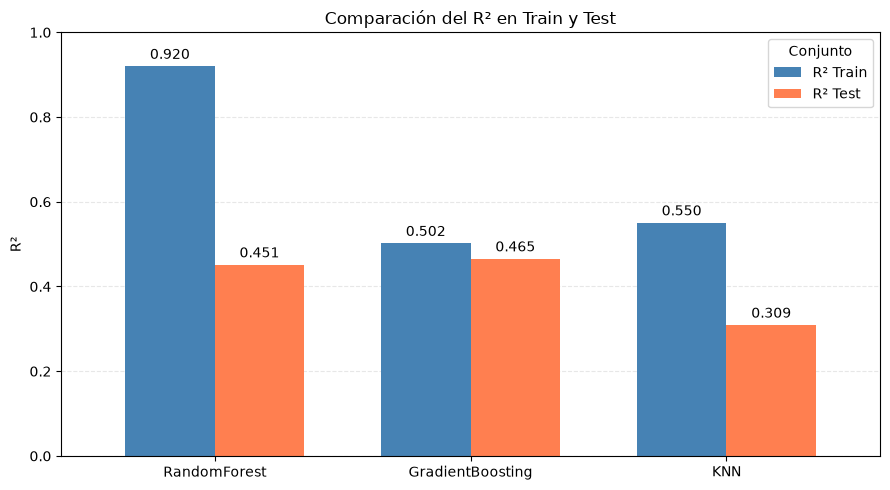

In [67]:
# Extraemos el R² de Train y Test para cada modelo
df_r2 = (
    df_default["R2"]
    .unstack("Conjunto")
    [["Train", "Test"]]
    .rename(columns={
        "Train": "R² Train",
        "Test": "R² Test"
    })
    .reset_index()
)

# Calculamos la diferencia entre Train y Test
df_r2["Diferencia"] = df_r2["R² Train"] - df_r2["R² Test"]

# Mostramos la tabla
display(df_r2.round(4))

# Gráfico
ax = df_r2.plot(
    x="Modelo",
    y=["R² Train", "R² Test"],
    kind="bar",
    figsize=(9, 5),
    rot=0,
    width=0.7,
    color=["steelblue", "coral"]
)

ax.set_title("Comparación del R² en Train y Test")
ax.set_xlabel("")
ax.set_ylabel("R²")
ax.set_ylim(0, 1)
ax.legend(title="Conjunto")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Mostrar valores sobre las barras
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

### Análisis de sobreajuste

Al comparar el R² entre entrenamiento y prueba, podemos ver diferencias bastante claras en cómo generalizan los tres modelos.

**Random Forest** presentó un sobreajuste considerable, con un R² de 0.919 en entrenamiento que cae a 0.453 en test, dejando una brecha de 0.466. Esto indica que el modelo se ajusta muy bien a los datos de entrenamiento, pero pierde bastante rendimiento al enfrentarse a datos nuevos.

Por su parte, **KNN** también mostró indicios de sobreajuste, aunque menos marcados, con una diferencia de 0.241 entre entrenamiento (0.550) y test (0.309). Además, fue el modelo que obtuvo el peor rendimiento predictivo.

En cambio, **Gradient Boosting** mostró un comportamiento mucho más equilibrado, con un R² de 0.502 en entrenamiento y 0.462 en test, es decir, una diferencia de apenas 0.040. Esto sugiere que logra generalizar bastante bien lo aprendido, sin mostrar señales importantes de sobreajuste.

En resumen, **Gradient Boosting fue el modelo que mejores resultados obtuvo inicialmente**, tanto por su rendimiento en test como por la poca diferencia respecto del entrenamiento. De todas formas, su ventaja sobre Random Forest en test fue bastante pequeña (0.462 frente a 0.453).

En la siguiente etapa, vamos a aplicar validación cruzada y optimización de hiperparámetros para intentar mejorar las predicciones y controlar el sobreajuste, especialmente en Random Forest y KNN.

## 4. Optimización
Con el objetivo de mejorar el desempeño predictivo y reducir el sobreajuste observado en algunos modelos, se realizaremos una búsqueda de hiperparámetros mediante RandomizedSearchCV, utilizando validación cruzada de 5 folds sobre el conjunto de entrenamiento.

Posteriormente, se compararán los resultados obtenidos con los modelos iniciales para evaluar si la optimización permitió mejorar su capacidad de generalización.

In [68]:
models_and_params = {
    'RandomForest': {
        'model': RandomForestRegressor(random_state=RANDOM_STATE),
        'preprocessor': preprocessor_trees,
        'params': {
            'regressor__n_estimators': randint(100, 600),
            'regressor__max_depth': randint(3, 25),
            'regressor__min_samples_split': randint(2, 20),
            'regressor__min_samples_leaf': randint(1, 15),
            'regressor__max_features': ['sqrt', 'log2', 0.5, 0.75, 1.0],
            'regressor__max_leaf_nodes': [None, 20, 50, 100, 200],
            'regressor__max_samples': [None, 0.6, 0.8, 1.0],
            'regressor__ccp_alpha': [0.0, 0.0001, 0.001, 0.01],
        }
    },
    'GradientBoosting': {
        'model': GradientBoostingRegressor(random_state=RANDOM_STATE),
        'preprocessor': preprocessor_trees,
        'params': {
            'regressor__n_estimators': randint(100, 600),
            'regressor__learning_rate': loguniform(0.01, 0.3),
            'regressor__max_depth': randint(2, 7),
            'regressor__subsample': uniform(0.6, 0.4),
            'regressor__min_samples_split': randint(2, 20),
            'regressor__min_samples_leaf': randint(1, 15),
            'regressor__max_features': [None, 'sqrt', 0.5, 0.75],
            'regressor__max_leaf_nodes': [None, 10, 20, 50],
            'regressor__loss': ['squared_error', 'huber'],
            'regressor__ccp_alpha': [0.0, 0.0001, 0.001],
        }
    },
    'KNN': {
        'model': KNeighborsRegressor(),
        'preprocessor': preprocessor_knn,
        'params': {
            'regressor__n_neighbors': randint(2, 50),
            'regressor__weights': ['uniform', 'distance'],
            'regressor__p': [1, 2, 3],
            'regressor__leaf_size': randint(15, 60),
        }
    },
}

In [69]:
def random_search_cv(X, y, modelo, parametros, n_iter, scoring, preprocessor=None):

    # Construimos el pipeline
    steps = []

    if preprocessor is not None:
        steps.append(("preprocessor", preprocessor))

    steps.append(("regressor", modelo))

    pipeline = Pipeline(steps)

    # Validación cruzada con 5 folds
    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    # Métricas de evaluación
    metricas = {
        "MAE": "neg_mean_absolute_error",
        "MSE": "neg_mean_squared_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    }

    # Búsqueda aleatoria de hiperparámetros
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parametros,
        n_iter=n_iter,
        scoring=metricas,
        refit=scoring,
        cv=cv,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )

    search.fit(X, y)

    # Recuperamos las métricas de cada fold
    # correspondientes a la mejor combinación de hiperparámetros
    best_idx = search.best_index_

    metricas_folds = []

    for fold in range(cv.get_n_splits()):
        metricas_folds.append({
            "Fold": fold + 1,
            "MAE": -search.cv_results_[f"split{fold}_test_MAE"][best_idx],
            "MSE": -search.cv_results_[f"split{fold}_test_MSE"][best_idx],
            "RMSE": -search.cv_results_[f"split{fold}_test_RMSE"][best_idx],
            "R2": search.cv_results_[f"split{fold}_test_R2"][best_idx]
        })

    df_metricas = pd.DataFrame(metricas_folds).set_index("Fold")

    display(df_metricas)
    print(f"\nMejor combinación de hiperparámetros: {search.best_params_}")

    return {
        "hyperparams": search.best_params_,
        "metricas": df_metricas,
        "best_estimator": search.best_estimator_
    }

In [70]:
resultados = {}

for nombre, config in models_and_params.items():

    print(f"{'='*15} {nombre} {'='*15}")

    resultados[nombre] = random_search_cv(
        X=X_train,
        y=y_train,
        modelo=config["model"],
        parametros=config["params"],
        n_iter=50,
        scoring="MSE",
        preprocessor=config["preprocessor"]
    )

=============== RandomForest ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.2914,0.1649,0.4061,0.4588
2,0.3113,0.1816,0.4262,0.4434
3,0.3010,0.1794,0.4235,0.4163
4,0.2972,0.1847,0.4298,0.4299
5,0.2926,0.1681,0.4100,0.4381



Mejor combinación de hiperparámetros: {'regressor__ccp_alpha': 0.0001, 'regressor__max_depth': 14, 'regressor__max_features': 0.5, 'regressor__max_leaf_nodes': None, 'regressor__max_samples': 1.0, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 18, 'regressor__n_estimators': 541}
=============== GradientBoosting ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.2802,0.1538,0.3922,0.4953
2,0.2994,0.1696,0.4118,0.4804
3,0.2942,0.1727,0.4156,0.4380
4,0.2895,0.1783,0.4223,0.4497
5,0.2841,0.1597,0.3997,0.4660



Mejor combinación de hiperparámetros: {'regressor__ccp_alpha': 0.0001, 'regressor__learning_rate': np.float64(0.013833507535062186), 'regressor__loss': 'squared_error', 'regressor__max_depth': 6, 'regressor__max_features': 0.5, 'regressor__max_leaf_nodes': 50, 'regressor__min_samples_leaf': 8, 'regressor__min_samples_split': 4, 'regressor__n_estimators': 548, 'regressor__subsample': np.float64(0.7531707499015159)}
=============== KNN ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.3001,0.1777,0.4216,0.4168
2,0.3162,0.1910,0.4371,0.4146
3,0.3090,0.1892,0.4350,0.3841
4,0.3121,0.2003,0.4476,0.3818
5,0.2991,0.1783,0.4222,0.4040



Mejor combinación de hiperparámetros: {'regressor__leaf_size': 16, 'regressor__n_neighbors': 22, 'regressor__p': 1, 'regressor__weights': 'distance'}


In [71]:
metricas = ["MAE", "MSE", "RMSE", "R2"]

df_resumen_cv = pd.DataFrame({
    nombre: res["metricas"][metricas].apply(
        lambda x: f"{x.mean():.4f} ± {x.std():.4f}"
    )
    for nombre, res in resultados.items()
}).T

display(df_resumen_cv)

,MAE,MSE,RMSE,R2
RandomForest,0.2987 ± 0.0080,0.1757 ± 0.0087,0.4191 ± 0.0104,0.4373 ± 0.0158
GradientBoosting,0.2895 ± 0.0077,0.1668 ± 0.0099,0.4083 ± 0.0122,0.4659 ± 0.0230
KNN,0.3073 ± 0.0075,0.1873 ± 0.0095,0.4327 ± 0.0109,0.4003 ± 0.0165


 Veamos estos resultados en boxplots para que sea mas facil de visualizar

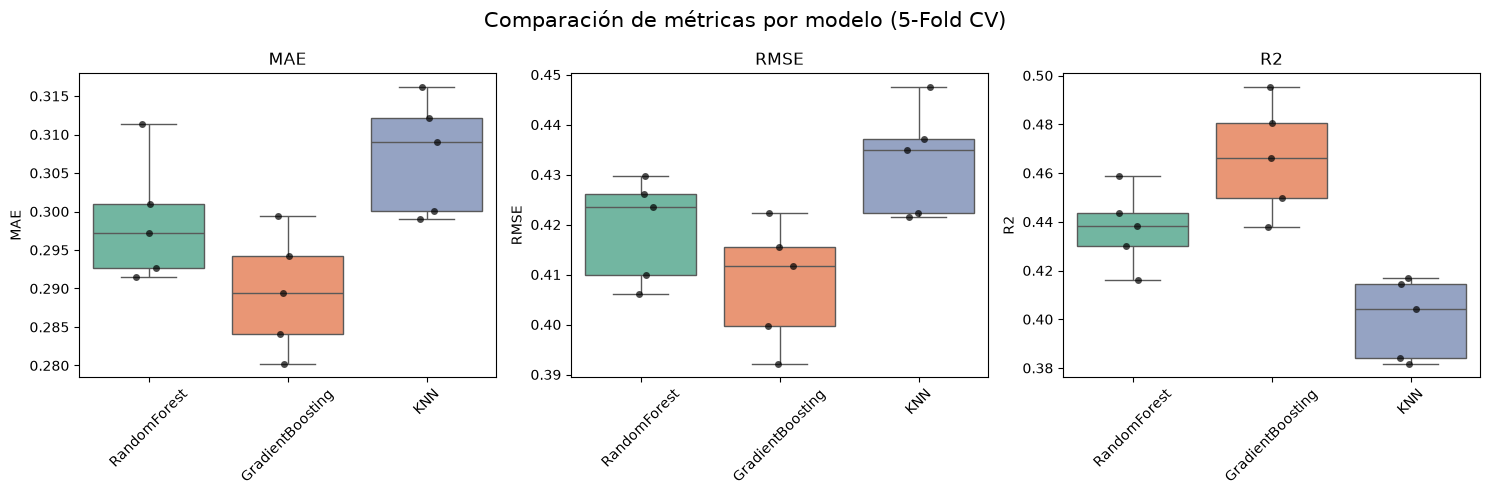

In [72]:
# Unificamos resultados en un solo dataframe
filas = []

for modelo, res in resultados.items():
    df = res["metricas"].copy().reset_index()   # recupera Fold como columna
    df["Modelo"] = modelo
    filas.append(df)

df_comparativo = pd.concat(filas, ignore_index=True)

metricas = ["MAE", "RMSE", "R2"]

modelos = df_comparativo["Modelo"].unique()

# Un color fijo por modelo
palette = dict(zip(modelos, sns.color_palette("Set2", n_colors=len(modelos))))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metrica in zip(axes, metricas):

    sns.boxplot(
        data=df_comparativo,
        x="Modelo",
        y=metrica,
        hue="Modelo",
        order=modelos,
        hue_order=modelos,
        palette=palette,
        dodge=False,
        showfliers=False,
        legend=False,
        ax=ax
    )

    sns.stripplot(
        data=df_comparativo,
        x="Modelo",
        y=metrica,
        order=modelos,
        color="black",
        alpha=0.7,
        jitter=True,
        size=5,
        ax=ax
    )

    ax.set_title(metrica)
    ax.set_xlabel("")
    ax.set_ylabel(metrica)
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Comparación de métricas por modelo (5-Fold CV)", fontsize=15)
plt.tight_layout()
plt.show()

A partir de los boxplots obtenidos mediante validación cruzada de 5 folds, se observa que los tres modelos presentan una variabilidad relativamente acotada en sus métricas, lo que sugiere un comportamiento razonablemente consistente entre las distintas particiones de los datos.

Gradient Boosting se destaca por obtener sistemáticamente los mejores resultados en MAE, RMSE y R², aunque presenta cierta variabilidad entre folds. Por su parte, Random Forest muestra resultados relativamente estables, pero con un rendimiento predictivo inferior, mientras que KNN presenta las peores métricas de manera consistente.

En conjunto, los resultados favorecen a Gradient Boosting por su mejor desempeño predictivo, aunque no necesariamente por presentar la menor dispersión entre folds.

## Testeo de los modelos

In [87]:
testeos_opt = {}

for nombre, res in resultados.items():
    testeos_opt[nombre] = entrenar_y_evaluar(
        res["best_estimator"],
        X_train,
        y_train,
        X_test,
        y_test
    )

    print(f"\n{'='*15} {nombre} {'='*15}")
    display(testeos_opt[nombre].round(4))


=============== RandomForest ===============


,MAE,MSE,RMSE,R2
Train,0.2491,0.1167,0.3416,0.6264
Test,0.2867,0.1646,0.4057,0.4559



=============== GradientBoosting ===============


,MAE,MSE,RMSE,R2
Train,0.2535,0.1246,0.3530,0.6012
Test,0.2770,0.1554,0.3943,0.4861



=============== KNN ===============


,MAE,MSE,RMSE,R2
Train,0.0000,0.0000,0.0000,1.0000
Test,0.2990,0.1783,0.4223,0.4105


In [93]:
df_ajuste_opt = pd.concat(
    testeos_opt,
    names=["Modelo", "Conjunto"]
)

display(df_ajuste_opt.round(4))

MAE    MSE   RMSE     R2
Modelo           Conjunto                            
RandomForest     Train    0.2491 0.1167 0.3416 0.6264
                 Test     0.2867 0.1646 0.4057 0.4559
GradientBoosting Train    0.2535 0.1246 0.3530 0.6012
                 Test     0.2770 0.1554 0.3943 0.4861
KNN              Train    0.0000 0.0000 0.0000 1.0000
                 Test     0.2990 0.1783 0.4223 0.4105

Veamos la diferencia entre train, test y validación

In [91]:
metricas_ajuste = []

for nombre, resultado in resultados.items():

    modelo = resultado["best_estimator"]

    # Predicciones
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    # Métricas de validación cruzada
    metricas_cv = resultado["metricas"].mean()

    metricas_ajuste.append({
        "Modelo": nombre,
        "R² Train": r2_score(y_train, pred_train),
        "R² CV": metricas_cv["R2"],
        "R² Test": r2_score(y_test, pred_test),
        "RMSE Train": np.sqrt(mean_squared_error(y_train, pred_train)),
        "RMSE CV": metricas_cv["RMSE"],
        "RMSE Test": np.sqrt(mean_squared_error(y_test, pred_test))
    })

df_ajuste = pd.DataFrame(metricas_ajuste).set_index("Modelo")

# Diferencia entre entrenamiento y validación
df_ajuste["Diferencia R²"] = (
    df_ajuste["R² Train"] - df_ajuste["R² CV"]
)

display(df_ajuste.round(4))

,R² Train,R² CV,R² Test,RMSE Train,RMSE CV,RMSE Test,Diferencia R²
Modelo,,,,,,,
RandomForest,0.6264,0.4373,0.4559,0.3416,0.4191,0.4057,0.1891
GradientBoosting,0.6012,0.4659,0.4861,0.3530,0.4083,0.3943,0.1353
KNN,1.0000,0.4003,0.4105,0.0000,0.4327,0.4223,0.5997


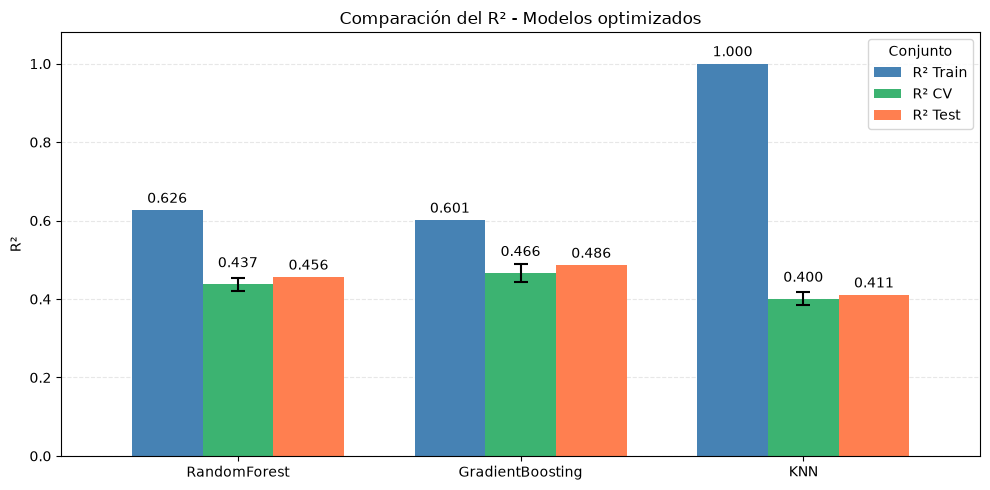

In [92]:
# Calculamos el desvío estándar del R² entre los 5 folds
std_cv = pd.Series({
    nombre: res["metricas"]["R2"].std()
    for nombre, res in resultados.items()
})

# Gráfico
ax = df_ajuste[
    ["R² Train", "R² CV", "R² Test"]
].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    width=0.75,
    color=["steelblue", "mediumseagreen", "coral"]
)

# Mostramos los valores sobre las barras
for i, container in enumerate(ax.containers):
    padding = 10 if i == 1 else 3  # CV es la segunda barra
    ax.bar_label(container, fmt="%.3f", padding=padding)

# Agregamos barras de error únicamente al R² CV
barras_cv = ax.containers[1]

x_cv = [
    barra.get_x() + barra.get_width() / 2
    for barra in barras_cv
]

ax.errorbar(
    x=x_cv,
    y=df_ajuste["R² CV"],
    yerr=std_cv.reindex(df_ajuste.index),
    fmt="none",
    ecolor="black",
    capsize=5,
    elinewidth=1.5,
    capthick=1.5
)

ax.set_title("Comparación del R² - Modelos optimizados")
ax.set_xlabel("")
ax.set_ylabel("R²")

# Ajustamos los límites para que entren las barras de error
r2_max = max(
    df_ajuste[["R² Train", "R² Test"]].max().max(),
    (df_ajuste["R² CV"] + std_cv.reindex(df_ajuste.index)).max()
)

ax.set_ylim(0, r2_max + 0.08)

ax.legend(title="Conjunto")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Comparamos con los modelos en default

In [89]:
nombres = [
    "Random Forest",
    "Gradient Boosting",
    "KNN"
]

comparacion = []

for nombre, fila in df_ajuste.iterrows():

    r2_train_default = df_default.loc[
        (nombre, "Train"), "R2"
    ]

    r2_test_default = df_default.loc[
        (nombre, "Test"), "R2"
    ]

    comparacion.append({
        "Modelo": nombre,
        "Brecha Default": r2_train_default - r2_test_default,
        "Brecha Optimizado": fila["R² Train"] - fila["R² Test"],
        "R² Test Default": r2_test_default,
        "R² Test Optimizado": fila["R² Test"]
    })

df_comparacion_ajuste = pd.DataFrame(comparacion).set_index("Modelo")

display(df_comparacion_ajuste.round(4))

,Brecha Default,Brecha Optimizado,R² Test Default,R² Test Optimizado
Modelo,,,,
RandomForest,0.4686,0.1705,0.4511,0.4559
GradientBoosting,0.0365,0.1151,0.4652,0.4861
KNN,0.2415,0.5895,0.3087,0.4105


### Análisis del sobreajuste después de la optimización

A partir de la comparación del R² entre entrenamiento, validación cruzada y prueba, podemos ver cómo cambió el comportamiento de los tres modelos después de optimizar sus hiperparámetros.

**Random Forest** logró reducir considerablemente el sobreajuste, pasando de una brecha de 0.4666 a 0.1695 entre entrenamiento y test. Sin embargo, la mejora predictiva fue muy pequeña, con un R² en test que pasó de 0.4528 a 0.4559.

**Gradient Boosting** sigue mostrando el mejor equilibrio entre ajuste y capacidad predictiva. Aunque su brecha aumentó de 0.0405 a 0.1126, consiguió mejorar su R² en test de 0.4618 a 0.4867, obteniendo el mejor resultado de los tres modelos. Además, los valores de validación cruzada (0.466) y test (0.487) son bastante cercanos, lo que es una buena señal de generalización.

Por último, **KNN** presentó el mayor sobreajuste, alcanzando un R² perfecto de 1.000 en entrenamiento, pero de apenas 0.400 en validación cruzada y 0.411 en test. A pesar de esto, fue el modelo que más mejoró su capacidad predictiva respecto de la configuración inicial, pasando de 0.3086 a 0.4105 en test.

En cuanto a las **barras de error de la validación cruzada**, se observa que son relativamente pequeñas para los tres modelos. Esto indica que sus resultados no varían demasiado entre los cinco folds, incluso en el caso de KNN, que presenta un fuerte sobreajuste. También es interesante que los valores de test se encuentran bastante cerca de los promedios de validación cruzada.

En conclusión, Si bien **Gradient Boosting obtuvo el mejor desempeño predictivo**, las diferencias respecto de Random Forest fueron relativamente pequeñas, tanto en validación cruzada como en test, con mejoras del R² de aproximadamente 0.028 y 0.031, respectivamente.
Por lo tanto, aunque Gradient Boosting se seleccionó como el mejor modelo por sus métricas, ambos algoritmos mostraron un rendimiento predictivo bastante similar.

# 5. Comparación final entre regresión lineal y Machine Learning

OLS permite interpretar las asociaciones entre los predictores y el precio mediante sus coeficientes. Para comparar su capacidad predictiva con Random Forest, Gradient Boosting y KNN, ajustamos adicionalmente la especificación completa del OLS sobre las mismas filas de entrenamiento de la sección 5 y evaluamos los cuatro modelos en las mismas filas de prueba.

La tabla presenta MAE, MSE, RMSE y R² de prueba para la variable objetivo log(1 + precio). Usamos RMSE como criterio principal y calculamos su reducción porcentual respecto del OLS:

$$
\text{Reducción del RMSE} =
\frac{\mathrm{RMSE}_{OLS}-\mathrm{RMSE}_{modelo}}
{\mathrm{RMSE}_{OLS}}\times 100
$$

Un porcentaje positivo indica un error menor que el OLS. Las especificaciones conservan las variables elegidas en cada sección, por lo que la comparación refleja el efecto conjunto del algoritmo y de los predictores empleados.

In [94]:
# Recuperamos las mismas filas de Train y Test con los predictores del OLS.
assert df.index.is_unique
datos_train_ols = df.loc[X_train.index]
datos_test_ols = df.loc[X_test.index]

modelo_ols_comparacion = smf.ols(
    formula=formula_completa, data=datos_train_ols, missing="raise"
).fit()
pred_ols_test = modelo_ols_comparacion.predict(datos_test_ols)
mse_ols_test = mean_squared_error(y_test, pred_ols_test)

metricas_ols_test = pd.DataFrame({
    "MAE": [mean_absolute_error(y_test, pred_ols_test)],
    "MSE": [mse_ols_test],
    "RMSE": [np.sqrt(mse_ols_test)],
    "R2": [r2_score(y_test, pred_ols_test)],
}, index=pd.Index(["OLS completo"], name="Modelo"))

comparacion_final = pd.concat([
    metricas_ols_test,
    df_ajuste_opt.xs("Test", level="Conjunto")[["MAE", "MSE", "RMSE", "R2"]],
])
rmse_ols = metricas_ols_test.loc["OLS completo", "RMSE"]
comparacion_final["Reducción RMSE vs OLS (%)"] = (
    (rmse_ols - comparacion_final["RMSE"]) / rmse_ols * 100
)
display(comparacion_final.sort_values("RMSE").round(4))

,MAE,MSE,RMSE,R2,Reducción RMSE vs OLS (%)
Modelo,,,,,
GradientBoosting,0.2770,0.1554,0.3943,0.4861,6.7701
RandomForest,0.2867,0.1646,0.4057,0.4559,4.0680
KNN,0.2990,0.1783,0.4223,0.4105,0.1466
OLS completo,0.3033,0.1788,0.4229,0.4088,0.0000


## COMPARACION FINAL

Entre los modelos evaluados, **GradientBoosting** obtuvo el mejor desempeño predictivo, con un RMSE de 0.3943 y un R² de 0.4861 en el conjunto de prueba. Esto representa una reducción del error del 6.95 % respecto del OLS completo. RandomForest también mostró resultados competitivos, aunque con una mejora menor, mientras que KNN obtuvo un rendimiento muy similar al OLS.

La elección de GradientBoosting también se apoya en los resultados de la sección anterior: después de optimizar sus hiperparámetros, mejoró su capacidad predictiva y mantuvo valores cercanos entre validación cruzada y prueba. Si bien RandomForest presentó una menor variabilidad entre folds, GradientBoosting consiguió mejores resultados en las métricas de evaluación.

Por su parte, **OLS aporta una perspectiva complementaria**, ya que permite interpretar como se relacionan la ubicación, la capacidad y las características de los alojamientos con el log-precio. De esta manera, mientras la regresión lineal ayuda a comprender estas asociaciones, GradientBoosting ofrece una mejor precisión para realizar predicciones.

En función de estos resultados, elegiríamos GradientBoosting como primera alternativa para generar referencias de precios. En la practica, el gestor podría utilizar sus predicciones para comparar los precios publicados de alojamientos con características similares y contar con un punto de referencia para la toma de decisiones. No obstante, estas estimaciones deben interpretarse junto con las particularidades de cada alojamiento y la información de mercado disponible.

# 6. Conclusiones generales

A lo largo de este trabajo analizamos los factores asociados al precio por noche de alojamientos de Airbnb en Milán y evaluamos distintos modelos para predecirlo.

**En primer lugar, el análisis exploratorio** permitió identificar que la ubicación, el tamaño y la capacidad de los alojamientos son algunas de las características más relacionadas con el precio. En particular, observamos diferencias importantes entre el municipio céntrico y las zonas periféricas. También encontramos una distribución de precios fuertemente asimétrica, por lo que utilizamos una transformación logarítmica para reducir la influencia de los valores extremos. Durante el preprocesamiento eliminamos inconsistencias y variables redundantes, conservando aquellas que consideramos relevantes para el problema.

**En cuanto al muestreo**, la extracción de 750 observaciones mediante un muestreo estratificado por barrio permitió conservar prácticamente las mismas proporciones geográficas que la base completa. La media de la variable objetivo presentó una diferencia de apenas el 0,47 %, aunque la varianza resultó aproximadamente un 10 % menor, posiblemente por la menor presencia de valores extremos. Esto sugiere que la muestra representa adecuadamente las características centrales de la población, aunque pierde parte de su variabilidad.

**La regresión lineal por OLS** permitió estudiar la asociación entre los predictores y el precio. En la base completa, el modelo obtuvo un R² de aproximadamente 0,395, mientras que en la muestra alcanzó 0,431. Sin embargo, al trabajar con menos observaciones aumentaron los errores estándar y varias variables perdieron significatividad estadística. Esto muestra cómo el tamaño de la muestra influye en la precisión de las estimaciones y en nuestra capacidad para identificar asociaciones. Además, comprobamos que eliminar regresores no significativos permitió simplificar los modelos sin modificar sustancialmente su bondad de ajuste. Las variables relacionadas con la ubicación, la capacidad del alojamiento y algunas características del anfitrión se mantuvieron entre las más relevantes.

**En la etapa de Machine Learning**, comparamos Random Forest, Gradient Boosting y KNN, utilizando validación cruzada de cinco folds y optimización de hiperparámetros. Gradient Boosting obtuvo los mejores resultados, con un R² de 0,4861 y un RMSE de 0,3943 en el conjunto de prueba. Random Forest también mostró un rendimiento competitivo, mientras que KNN presentó un sobreajuste considerable después de la optimización. Si bien Gradient Boosting también mostró cierta diferencia entre entrenamiento y prueba, sus resultados de validación cruzada fueron relativamente cercanos a los obtenidos en test, lo que constituye una señal favorable sobre su capacidad de generalización.

**Al comparar directamente OLS con Machine Learning**, utilizando el mismo conjunto de prueba, Gradient Boosting logró reducir el RMSE un 6,77 % respecto de la regresión lineal y aumentar el R² de 0,4088 a 0,4861. Esta mejora muestra que los modelos no lineales pueden capturar relaciones más complejas entre las características de los alojamientos y sus precios. Sin embargo, OLS conserva una ventaja importante en términos de interpretabilidad, ya que permite cuantificar y analizar las asociaciones entre cada predictor y la variable objetivo.

**En función de estos resultados, elegiríamos Gradient Boosting para una aplicación orientada a la predicción de precios**, utilizando OLS como una herramienta complementaria para interpretar las relaciones observadas. Por ejemplo, el modelo predictivo podría servir como referencia para que propietarios o administradores comparen sus tarifas con las estimadas para alojamientos de características similares.

De todas formas, reconocemos que **todavía existe un margen importante de mejora**: incluso el mejor modelo explica menos de la mitad de la variabilidad observada en el logaritmo del precio. La incorporación de información adicional, como la superficie en metros cuadrados, la proximidad a puntos de interés, la estacionalidad o las condiciones del mercado, podría mejorar las predicciones. Además, antes de utilizarlo en producción sería necesario evaluar su desempeño con datos más recientes y monitorear posibles cambios en el mercado.

En definitiva, el trabajo nos permitió comprobar que **la interpretabilidad estadística y la capacidad predictiva son objetivos complementarios**. Mientras la regresión lineal ayuda a comprender las asociaciones presentes en los datos, Gradient Boosting ofrece una mayor precisión para estimar precios. La elección entre ambos depende, por lo tanto, del objetivo concreto de la aplicación.